In [1]:
""" Import required libraries
"""
import torch
import scipy.io as sio
import numpy as np
import netCDF4 as nc
import deepxde as dde
import pinnicle as pinn
import matplotlib.tri as tri
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap, LogNorm
from matplotlib.artist import Artist
from matplotlib.path import Path
from mpl_toolkits.axes_grid1 import make_axes_locatable
from tqdm import tqdm
import cmcrameri.cm as cmc
dde.config.set_default_float('float32')
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
from pyproj import Transformer
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerBase
from matplotlib.image import BboxImage
from matplotlib.transforms import Bbox
import matplotlib.colors as mcolors
import geopandas as gpd
from scipy.interpolate import griddata
import pandas as pd

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


Set the default float type to float64
Set the default float type to float32


In [3]:
""" specify data paths
"""
glacier = "Byrd-BMap3GL"
size = "30" + "ma"

model = "MC_exact_Helm"

homepath = '/private/var/phys-admin/Documents/Jakob/MC-SSA'
datapath = homepath + '/data/'
figurepath = homepath + '/figures/'
folder = homepath + '/MC-SSA/domains/'
pdatapath = homepath + '/processed-data/'

# for Gadi runs
outline = folder + f"{glacier}-{size}-vertices.exp"

dHdt_il = folder + 'ItsLIVE_dHdt_2013-18_mps.mat'
smb_noell = folder + 'Noell_RACMO_smb_2013-17_mps.mat'
app_mb = folder + 'apparent_mass_balance_2013-17_mps.mat'

# H_radar = pdatapath + 'UTIG-2009-ICECAP-BM3-500m-median-thk.mat'
# H_radar = pdatapath + 'NASA-2011-ICEBRIDGE-BM3-500m-median-thk.mat'
H_radar = pdatapath + 'Byrd-ICEBRIDGE-ICECAP-BM3-500m-median-thk.mat'
# H_radar = pdatapath + 'UTIG-2010-ICECAP-AIR-BM3-120m-median-thk.mat'
# H_radar = pdatapath + 'NASA-2011-ICEBRIDGE-BM2-120m-median-thk.mat'
H_radar2 = pdatapath + 'Byrd-ICEBRIDGE-ICECAP-BM3-120m-median-thk.mat'

bm3 = datapath + 'measures_data/BedMachineAntarctica-v3.nc'
bmap3 = datapath + '/BedMap3-radar-thk-profiles/bedmap3.nc'
meas = datapath + 'measures_data/antarctic_ice_vel_phase_map_v01_seconds.nc'

ICECAP_lines = datapath + '/BedMap3-radar-thk-profiles/UTIG_2009_ICECAP_AIR_BM3_Lines.gpkg'
ICEBRIDGE_lines = datapath + '/BedMap3-radar-thk-profiles/NASA_2011_ICEBRIDGE_AIR_BM2_Lines.gpkg'

ICEBRIDGE2019_lines = datapath + '/BedMap3-radar-thk-profiles/StatSumPoints500m/NASA_2019_ICEBRIDGE_AIR_BM3_Lines.gpkg'
EAGLE_lines = datapath + '/BedMap3-radar-thk-profiles/StatSumPoints500m/UTIG_2016_EAGLE_AIR_BM3_Lines.gpkg'
BAS_lines = datapath + '/BedMap3-radar-thk-profiles/StatSumPoints500m/BAS_2005_WISE-ISODYN_AIR_BM2_Lines.gpkg'

ICECAP_points = datapath + '/BedMap3-radar-thk-profiles/bedmap3_raw_data/UTIG_2010_ICECAP_AIR_BM3.csv'
ICEBRIDGE_points = datapath + '/BedMap3-radar-thk-profiles/bedmap2_raw_data/NASA_2011_ICEBRIDGE_AIR_BM2.csv'

ICECAP_stat_points = datapath + '/UTIG-2009-ICECAP-BM3-500m-points-med-thk.csv'

outFile = glacier
modelFolder = 'MC-SSA/Models/' + outFile 

In [4]:
""" load the required data
"""
ds_vel = nc.Dataset(meas)
# ds_vel = nc.Dataset(itslive)
ds_geom = nc.Dataset(bm3)
# ds_geom = nc.Dataset(rema)
ds_bmap = nc.Dataset(bmap3)

ds_H = sio.loadmat(H_radar)
ds_H2 = sio.loadmat(H_radar2)
ds_dH = sio.loadmat(dHdt_il)
# ds_smb = sio.loadmat(smb_noell)
ds_smb = sio.loadmat(app_mb)

ibridge = gpd.read_file(ICEBRIDGE_lines)
icap = gpd.read_file(ICECAP_lines)

In [5]:
ibridge2019 = gpd.read_file(ICEBRIDGE2019_lines)
eagle2016 = gpd.read_file(EAGLE_lines)
bas = gpd.read_file(BAS_lines)

In [6]:
ibridge_points = pd.read_csv(ICEBRIDGE_points,skiprows=18)
icap_points = pd.read_csv(ICECAP_points,skiprows=18)
icap_stat_points = pd.read_csv(ICECAP_stat_points)

In [7]:
""" create relevant the coordinate arrays and grids 
"""
# load data

x_v = ds_vel['x'][:]
y_v = ds_vel['y'][:]
x_g = ds_geom['x'][:]
y_g = ds_geom['y'][:]
x_b2 = ds_bmap['x'][:]
y_b2 = ds_bmap['y'][:]
x_H = ds_H['x'][:]
y_H = ds_H['y'][:]
x_H2 = ds_H2['x'][:]
y_H2 = ds_H2['y'][:]
x_dH = ds_dH['x'][:]
y_dH = ds_dH['y'][:]
x_smb = ds_smb['x'][:]
y_smb = ds_smb['y'][:]

# BM3, Measures
vx = ds_vel['VX']
vy = ds_vel['VY']
s = ds_bmap['surface_topography']
b = ds_geom['thickness']
H = ds_H['median-thickness']
H2 = ds_H2['median-thickness']
dH = ds_dH['dHdt-2013-18']
# smb = ds_smb['smb-2013-17']
smb = ds_smb['a-2013-17']
bed = ds_geom['bed']
bed2 = ds_bmap['bed_topography']
s2 = ds_geom['surface']

# # Rema, ItsLive
# vx = ds_vel['vx']
# vy = ds_vel['vy']
# s = ds_geom['__xarray_dataarray_variable__']
# H = ds_H['H']

# thickness
b = ds_geom['thickness']
b2 = ds_bmap['ice_thickness']
b2flmask = np.where(ds_bmap['thickness_uncertainty'][:] < 13., 1, 0)
b2fl = np.where(b2flmask,b2,np.nan)

vertices = np.loadtxt(outline,delimiter=' ',skiprows=5)
minx = np.min(vertices[:,0])
maxx = np.max(vertices[:,0])
miny = np.min(vertices[:,1])
maxy = np.max(vertices[:,1])
minmax = [minx, maxx, miny, maxy]


# create masks

extension = 0. #10e3

xvmask = np.where(np.logical_and(x_v>(minx-extension),x_v<(maxx+extension)))[0]
yvmask = np.where(np.logical_and(y_v>(miny-extension),y_v<(maxy+extension)))[0]

xsmask = np.where(np.logical_and(x_g>(minx-extension),x_g<(maxx+extension)))[0]
ysmask = np.where(np.logical_and(y_g>(miny-extension),y_g<(maxy+extension)))[0]

xb2mask = np.where(np.logical_and(x_b2>(minx-extension),x_b2<(maxx+extension)))[0]
yb2mask = np.where(np.logical_and(y_b2>(miny-extension),y_b2<(maxy+extension)))[0]

# xdHmask = np.where(np.logical_and(x_dH>(minx-extension),x_dH<(maxx+extension)))[0]
# ydHmask = np.where(np.logical_and(y_dH>(miny-extension),y_dH<(maxy+extension)))[0]

Hmask = np.where(np.logical_and(
    np.logical_and(x_H>(minx-extension),x_H<(maxx+extension)),
    np.logical_and(y_H>(miny-extension),y_H<(maxy+extension))
    ))

H2mask = np.where(np.logical_and(
    np.logical_and(x_H2>(minx-extension),x_H2<(maxx+extension)),
    np.logical_and(y_H2>(miny-extension),y_H2<(maxy+extension))
    ))

dHmask = np.where(np.logical_and(
    np.logical_and(x_dH>(minx-extension),x_dH<(maxx+extension)),
    np.logical_and(y_dH>(miny-extension),y_dH<(maxy+extension))
    ))

smbmask = np.where(np.logical_and(
    np.logical_and(x_smb>(minx-extension),x_smb<(maxx+extension)),
    np.logical_and(y_smb>(miny-extension),y_smb<(maxy+extension))
    ))



# crop data

vxcrop = vx[yvmask,:]
vxcrop = vxcrop[:,xvmask]
vycrop = vy[yvmask,:]
vycrop = vycrop[:,xvmask]

scrop = s[yb2mask,:]
scrop = scrop[:,xb2mask]

s2crop = s2[ysmask,:]
s2crop = s2crop[:,xsmask]

bedcrop = bed[ysmask,:]
bedcrop = bedcrop[:,xsmask]

bed2crop = bed2[yb2mask,:]
bed2crop = bed2crop[:,xb2mask]

bcrop = b[ysmask,:]
bcrop = bcrop[:,xsmask]

b2crop = b2[yb2mask,:]
b2crop = b2crop[:,xb2mask]

b2flcrop = b2fl[yb2mask,:]
b2flcrop = b2flcrop[:,xb2mask]

# dHcrop = dH[ydHmask,:]
# dHcrop = dHcrop[:,xdHmask]

H_crop = H[Hmask]
H2_crop = H2[H2mask]
dH_crop = dH[dHmask]
smb_crop = smb[smbmask]


# grid data

Xv,Yv = np.meshgrid(x_v[xvmask],y_v[yvmask])
Xvf = Xv.flatten()
Yvf = Yv.flatten()
Xvf = Xvf.reshape((Xvf.size,1))
Yvf = Yvf.reshape((Yvf.size,1))
XYv = np.hstack((Xvf,Yvf))

Xs,Ys = np.meshgrid(x_g[xsmask],y_g[ysmask])
Xsf = Xs.flatten()
Ysf = Ys.flatten()
Xsf = Xsf.reshape((Xsf.size,1))
Ysf = Ysf.reshape((Ysf.size,1))
XYs = np.hstack((Xsf,Ysf))

Xb2,Yb2 = np.meshgrid(x_b2[xb2mask],y_b2[yb2mask])
Xb2f = Xb2.flatten()
Yb2f = Yb2.flatten()
Xb2f = Xb2f.reshape((Xb2f.size,1))
Yb2f = Yb2f.reshape((Yb2f.size,1))
XYb2 = np.hstack((Xb2f,Yb2f))

# XdH,YdH = np.meshgrid(x_dH[xdHmask],y_dH[ydHmask])
# XdHf = XdH.flatten()
# YdHf = YdH.flatten()
# XdHf = XdHf.reshape((XdHf.size,1))
# YdHf = YdHf.reshape((YdHf.size,1))
# XYdH = np.hstack((XdHf,YdHf))

XH = x_H[Hmask]
YH = y_H[Hmask]
XH = XH.reshape((XH.size,1))
YH = YH.reshape((YH.size,1))
XYH = np.hstack((XH,YH))

XH2 = x_H2[H2mask]
YH2 = y_H2[H2mask]
XH2 = XH2.reshape((XH2.size,1))
YH2 = YH2.reshape((YH2.size,1))
XYH2 = np.hstack((XH2,YH2))

XdH = x_dH[dHmask]
YdH = y_dH[dHmask]
XdH = XdH.reshape((XdH.size,1))
YdH = YdH.reshape((YdH.size,1))
XYdH = np.hstack((XdH,YdH))

Xsmb = x_smb[smbmask]
Ysmb = y_smb[smbmask]
Xsmb = Xsmb.reshape((Xsmb.size,1))
Ysmb = Ysmb.reshape((Ysmb.size,1))
XYsmb = np.hstack((Xsmb,Ysmb))

In [8]:
""" some constants 
"""
cm = 1/2.54  # figsize conversion factor, centimeters in inches
spy = 31536000  # seconds per year
fs = 8  # fontsize

In [9]:
""" projection
"""
proj = ccrs.SouthPolarStereo()
transformer = Transformer.from_crs(4326, 3031, always_xy=True)

In [10]:
""" constrain plot area
"""
poly_path = Path(vertices)
inside_v = poly_path.contains_points(XYv)
inside_s = poly_path.contains_points(XYs)
inside_b = poly_path.contains_points(XYb2)
inside_H = poly_path.contains_points(XYH)
inside_smb = poly_path.contains_points(XYsmb)

/opt/miniconda3/envs/ddeenv/lib/python3.10/site-packages/cartopy/mpl/geoaxes.py:1631: UserWarning: The following kwargs were not used by contour: 'color'
  result = super().contourf(*args, **kwargs)


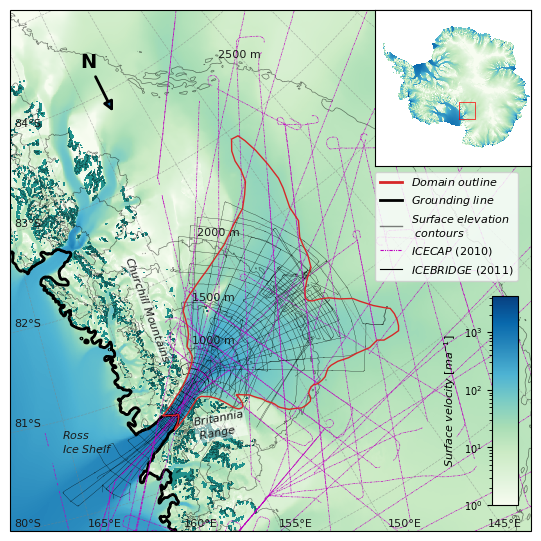

In [ ]:
## geographical setting
# runtime ca 3.5 min

vel = np.sqrt(vx[:]**2 + vy[:]**2)
vel = vel*spy
xv,yv = np.meshgrid(x_v,y_v)
xs,ys = np.meshgrid(x_b2,y_b2)
groundingline = np.where(np.logical_or(ds_bmap['mask'][:]==1,ds_bmap['mask'][:]==4),1,0)
rock = np.where(ds_bmap['mask'][:]==4,1,np.nan)

x0 = 0.2e6
x1 = 0.8e6
y0 = -1.1e6
y1 = -0.5e6

cmap = 'GnBu'
vmin = 1e0

fig,ax = plt.subplots(nrows=1,ncols=1,figsize=[14*cm,14*cm],subplot_kw={"projection": proj})

a = ax.pcolormesh(xv,yv,vel,norm=LogNorm(vmin=vmin),cmap=cmap,transform=proj)
b = ax.contour(xs,ys,s[:],levels=[1000,1500,2000,2500,3000],linewidths=0.5,alpha=0.5,colors='k',transform=proj)
c = ax.contour(xs,ys,groundingline,[0.5],linewidths=2,colors='k',transform=proj)
d = ax.contourf(xs,ys,rock,transform=proj,levels=[0.5,1.5],color=['tab:gray'])

ibridge.plot(ax=ax, color="k",alpha=1, linewidth=0.2, linestyle='solid')# ':')
icap.plot(ax=ax, color="m", linewidth=0.5, linestyle=(0, (3, 1, 1, 1, 1, 1)))# 'dashed')



outline = Polygon(vertices, closed=True, fill=False, edgecolor='tab:red',linewidth=1)
e = ax.add_patch(outline)
e.set_zorder(5)

ax.set_xlim(x0,x1)
ax.set_ylim(y0,y1)

ax.set_aspect(1)
ax.set(yticklabels=[])
ax.set(xticklabels=[])

cax = ax.inset_axes([0.925,0.05,0.05,0.4])
cbar = fig.colorbar(a, cax=cax,orientation='vertical')#, location="right", pad=0.05, shrink=0.88)
cbar.ax.tick_params(labelsize=fs-1)
# cbar.ax.set_title('$Surface\ velocity\ [m a^{-1}]$',fontsize=fs-1)#,x=1.3,pad=-0)
cbar.set_label('$Surface\ velocity\ [m a^{-1}]$',fontsize=fs)
cbar.ax.yaxis.set_ticks_position('left')
cbar.ax.yaxis.set_label_position('left')

gl = ax.gridlines(
crs=ccrs.PlateCarree(),
draw_labels=False,      # don't label the outside
linewidth=0.5,
color='gray',
alpha=0.5,
linestyle='--'
)
# gl.zorder = 1
gl.xlocator = mticker.FixedLocator(range(-180, 181, 5))
gl.ylocator = mticker.FixedLocator(range(-90, -59, 1))

# Surface elevation labels
for el,xx,yy in zip([1000,1500,2000,2500],[410000,410000,415000,440000],[-885000,-835000,-760000,-555000]):
    ax.text(
        xx, yy,
        f"{el} m",
        fontsize=fs,
        color="0.1",
        bbox=dict(
            facecolor="none",
            edgecolor="none",   # or "black"
            alpha=0.8,
            pad=0.1
        )
    )

# Latitude labels
for lat,yy in zip(range(-84, -79, 1),[-635000,-750000,-865000,-980000,-1095000]):
    ax.text(
        205000, yy,
        f"{-1*lat}°S",
        fontsize=fs,
        color="0.1",
        bbox=dict(
            facecolor="none",
            edgecolor="none",   # or "black"
            alpha=0.8,
            pad=0.1
        )
    )

# Longitude labels
for lon,xx in zip([165,160,155,150,145],[290000,400000,510000,635000,750000]):
    ax.text(
        xx, -1095000,
        f"{lon}°E",
        fontsize=fs,
        color="0.1",
        bbox=dict(
            facecolor="none",
            edgecolor="none",   # or "black"
            alpha=0.8,
            pad=0.1
        )
    )

axins = ax.inset_axes([0.7,0.7,0.3,0.3])
axins.pcolormesh(xv,yv,vel,norm=LogNorm(vmin=vmin),cmap=cmap)
axins.plot([x0,x1,x1,x0,x0],[y0,y0,y1,y1,y0],color='red',linewidth=0.5)
axins.set(yticklabels=[])
axins.set(xticklabels=[])
axins.set(xticks=[])
axins.set(yticks=[])

fig.tight_layout()

legend_surf = Line2D([0], [0],linewidth=1,alpha=0.5,color='k',label='$Surface\ elevation$')
legend_gl = Line2D([0], [0],linewidth=2,color='k',label='$Grounding\ line$')
# legend_rock = Line2D([0],[0],linewidth=4,color='tab:gray')
legend_domain = Line2D([0],[0],linewidth=2,color='tab:red')
legend_icap = Line2D([0],[0],linewidth=0.8,color='m',linestyle=(0, (3, 1, 1, 1, 1, 1)))# 'dashed')
legend_ibridge = Line2D([0],[0],linewidth=0.8,color='k',linestyle='solid')# ':')

ax.legend(
    loc="upper left",
    bbox_to_anchor=(0.69, 0.7),
    # mode='expand',
    frameon=True,
    fontsize=fs,
    handles=[legend_domain,legend_gl,legend_surf,legend_icap,legend_ibridge],#,legend_gradient],
    labels=['$Domain\ outline$','$Grounding\ line$', '$Surface\ elevation$\n $contours$', '$ICECAP\ (2010)$', '$ICEBRIDGE\ (2011)$'],#,'$Surface\ velocity\ [m a^{-1}$]'],
)

ax.annotate(
    "N",
    xy=(0.2, 0.8),          # arrow tip, in axes coordinates
    xytext=(0.15, 0.90),       # text position
    xycoords="axes fraction",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold",
    arrowprops=dict(arrowstyle="-|>", lw=2)
)

ax.text(
        4.1e5, -9.95e5,
        f"$Britannia$\n $Range$",
        fontsize=fs,
        color='0.1',
        rotation=10,
        bbox=dict(
            facecolor="white",
            edgecolor="none",   # or "black"
            alpha=0.5,
            pad=0.1
        )
    )

ax.text(
        3.3e5, -9.05e5,
        f"$Churchill\ Mountains$",
        fontsize=fs,
        color='0.1',
        rotation=-70,
        bbox=dict(
            facecolor="white",
            edgecolor="none",   # or "black"
            alpha=0.5,
            pad=0.1
        )
    )

ax.text(
        2.6e5, -10.1e5,
        f"$Ross$\n$Ice\ Shelf$",
        fontsize=fs,
        color="0.1",
        rotation=0,
        bbox=dict(
            facecolor="none",
            edgecolor="none",   # or "black"
            alpha=0.8,
            pad=0.1
        )
    )

plt.savefig(f'{figurepath}Fig-geogr-setting.jpg',dpi=900,pad_inches=0.,bbox_inches=None)

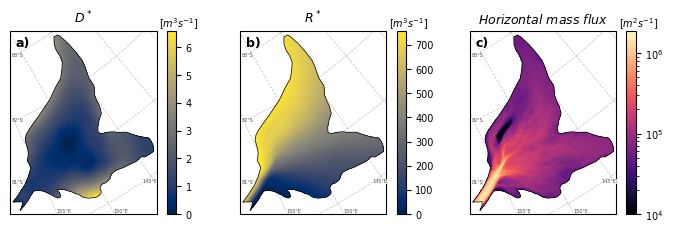

In [59]:
## D,R

# data = sio.loadmat(f'{homepath}/saved-data/exp1-potentials-and-mass-flux-Measures-grid.mat')
# X = data['x']
# Y = data['y']
# D = data['mean_D']
# R = data['mean_R']
# mf = data['mean_MF']

data = sio.loadmat(f'{homepath}/saved-data/exp1-No1-potentials-and-mass-flux-Measures-grid.mat')
X = data['x']
Y = data['y']
D = data['D']
R = data['R']
mf = data['MF']


fig, ((ax1,ax2,ax3)) = plt.subplots(nrows=1,ncols=3,figsize=[17.9*cm,6*cm],subplot_kw={"projection": proj})

a1 = ax1.pcolormesh(X,Y,D.reshape((Xv.shape[0],Xv.shape[1])),cmap='cividis',shading='gouraud',transform=proj)
a2 = ax2.pcolormesh(X,Y,R.reshape((Xv.shape[0],Xv.shape[1])),cmap='cividis',shading='gouraud',transform=proj)
a3 = ax3.pcolormesh(X,Y,(mf).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap='magma',norm=LogNorm(vmin=1e4),transform=proj)

for ax,a in zip([ax1, ax2, ax3],[a1, a2, a3]):
    outline = Polygon(vertices, closed=True, fill=False, edgecolor='black',linewidth=0.5)
    ax.add_patch(outline)
    Artist.set_clip_path(a,outline)
    ax.set_aspect(1)
    ax.set(yticklabels=[])
    ax.set(xticklabels=[])

    ax.margins(x=0.02, y=0.02)

    gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=False,      # don't label the outside
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
    )
    gl.zorder = 0
    gl.xlocator = mticker.FixedLocator(range(-180, 181, 5))
    gl.ylocator = mticker.FixedLocator(range(-90, -59, 1))

    # Latitude labels
    for lat,y0 in zip(range(-83, -80, 1),[-687000,-812000,-932000]):
        ax.text(
            373000, y0,
            f"{-1*lat}°S",
            fontsize=3.5,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )

    # Longitude labels
    for lon,x0,y0 in zip([155,150,145],[460000,570000,625000],[-987000,-987000,-930000]):
        ax.text(
            x0, y0,
            f"{lon}°E",
            fontsize=3.5,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )
    
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.88)
    cbar.ax.tick_params(labelsize=fs-1)
    if ax == ax1:
        cbar.ax.set_title('$[m^3 s^{-1}]$',fontsize=fs-1,x=1.3,pad=-0)
    elif ax == ax2:
        cbar.ax.set_title('$[m^3 s^{-1}]$',fontsize=fs-1,x=1.3,pad=-0)
    elif ax == ax3:
        cbar.ax.set_title('$[m^2 s^{-1}]$',fontsize=fs-1,x=1.3,pad=-0)



# a,b,c
for label,ax in zip(['a','b','c'],[ax1,ax2,ax3]):
    ax.text(
        0.04, 0.97, f'{label})',
        transform=ax.transAxes,
        fontsize=fs+1,
        fontweight='bold',
        va='top',
        ha='left'
    )

ax1.set_title('$D^*$',fontsize=fs+1)
ax2.set_title('$R^*$',fontsize=fs+1)
ax3.set_title('$Horizontal\ mass\ flux$',fontsize=fs+1)

fig.tight_layout()
    
plt.savefig('/private/var/phys-admin/Documents/Jakob/MC-SSA/figures/Fig-mass-flux.jpg',dpi=600,pad_inches=0.,bbox_inches=None)


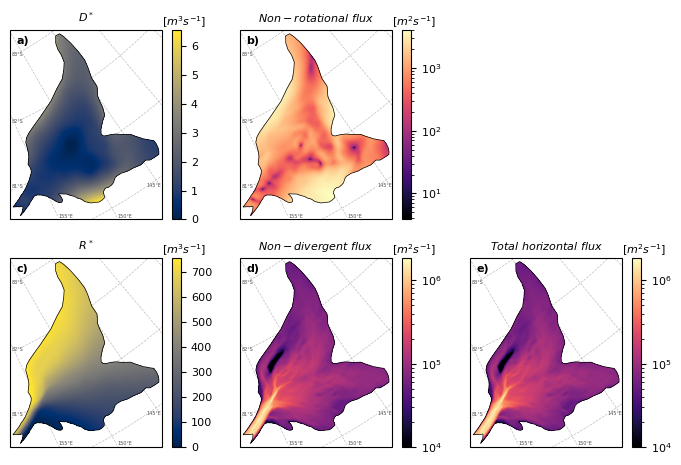

In [60]:
## Suppl. figure, gradients/flux components from the two component fields

data = sio.loadmat(f'{homepath}/saved-data/exp1-No1-potentials-and-mass-flux-Measures-grid.mat')
X = data['x']
Y = data['y']
D = data['D']
R = data['R']
mf = data['MF']
mfd = data['MF_div']
mfr = data['MF_rot']


fig, ((ax1,ax2,ax3),(ax4,ax5,ax6)) = plt.subplots(nrows=2,ncols=3,figsize=[17.9*cm,12*cm],subplot_kw={"projection": proj})

a1 = ax1.pcolormesh(X,Y,D.reshape((Xv.shape[0],Xv.shape[1])),cmap='cividis',shading='gouraud',transform=proj)
a2 = ax2.pcolormesh(X,Y,(mfd).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap='magma',norm=LogNorm(),transform=proj)
a4 = ax4.pcolormesh(X,Y,R.reshape((Xv.shape[0],Xv.shape[1])),cmap='cividis',shading='gouraud',transform=proj)
a5 = ax5.pcolormesh(X,Y,(mfr).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap='magma',norm=LogNorm(vmin=1e4),transform=proj)
a6 = ax6.pcolormesh(X,Y,(mf).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap='magma',norm=LogNorm(vmin=1e4),transform=proj)

for ax,a in zip([ax1, ax2, ax4,ax5,ax6],[a1, a2, a4,a5,a6]):
    outline = Polygon(vertices, closed=True, fill=False, edgecolor='black',linewidth=0.5)
    ax.add_patch(outline)
    Artist.set_clip_path(a,outline)
    ax.set_aspect(1)
    ax.set(yticklabels=[])
    ax.set(xticklabels=[])

    ax.margins(x=0.02, y=0.02)

    gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=False,      # don't label the outside
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
    )
    gl.zorder = 0
    gl.xlocator = mticker.FixedLocator(range(-180, 181, 5))
    gl.ylocator = mticker.FixedLocator(range(-90, -59, 1))

    # Latitude labels
    for lat,y0 in zip(range(-83, -80, 1),[-687000,-812000,-932000]):
        ax.text(
            373000, y0,
            f"{-1*lat}°S",
            fontsize=3.5,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )

    # Longitude labels
    for lon,x0,y0 in zip([155,150,145],[460000,570000,625000],[-987000,-987000,-930000]):
        ax.text(
            x0, y0,
            f"{lon}°E",
            fontsize=3.5,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )
    
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.88)
    cbar.ax.tick_params(labelsize=fs)
    if ax in [ax1,ax4]:
        cbar.ax.set_title('$[m^3 s^{-1}]$',fontsize=fs,x=1.3,pad=-0)
    else:
        cbar.ax.set_title('$[m^2 s^{-1}]$',fontsize=fs,x=1.3,pad=-0)



# a,b,c
for label,ax in zip(['a','b','c','d','e'],[ax1,ax2,ax4,ax5,ax6]):
    ax.text(
        0.04, 0.97, f'{label})',
        transform=ax.transAxes,
        fontsize=fs,
        fontweight='bold',
        va='top',
        ha='left'
    )

ax1.set_title('$D^*$',fontsize=fs)
ax2.set_title('$Non-rotational\ flux$',fontsize=fs)
ax4.set_title('$R^*$',fontsize=fs)
ax5.set_title('$Non-divergent\ flux$',fontsize=fs)
ax6.set_title('$Total\ horizontal\ flux$',fontsize=fs)

ax3.axis('off')

fig.tight_layout()
    
plt.savefig('/private/var/phys-admin/Documents/Jakob/MC-SSA/figures/Fig-suppl-flux-components.jpg',dpi=1200,pad_inches=0.,bbox_inches=None)


/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_78051/1762430767.py:41: RuntimeWarning: divide by zero encountered in divide
  H_drel = H_diff/Hprofile.flatten()
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_78051/1762430767.py:80: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect1,conn1 = ax3.indicate_inset_zoom(axins1, edgecolor="black")
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_78051/1762430767.py:81: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect2,conn2 = ax3.indicate_inset_zoom(axins2, edgecolor="black")


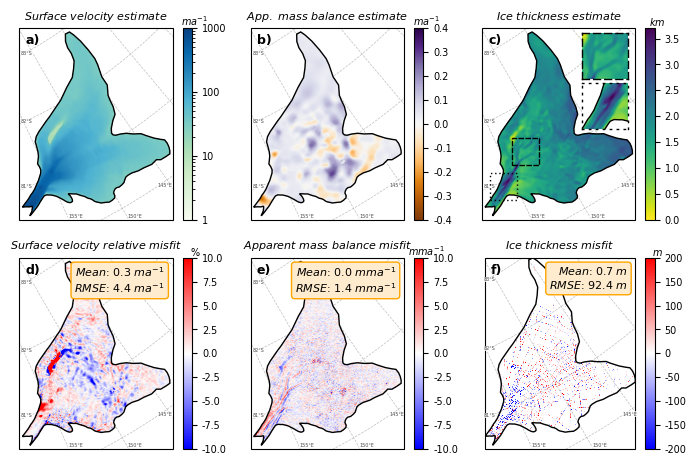

In [61]:
# prediction vs observations

# grid the radar lines
xg = np.unique(XH)
yg = np.unique(YH)
ix = np.searchsorted(xg,XH)
iy = np.searchsorted(yg,YH)
Hprofile = np.full((len(yg),len(xg)),np.nan)
Hprofile[iy,ix] = H_crop.reshape([len(H_crop),1])
Hprofile = np.flipud(Hprofile)

fig, ((ax1,ax2,ax3),(ax4,ax5,ax6)) = plt.subplots(nrows=2,ncols=3,figsize=[17.9*cm,12*cm], subplot_kw={'projection':proj})

data1 = sio.loadmat(f'{homepath}/saved-data/exp1-ice-thickness-BedMap-grid.mat')
data2 = sio.loadmat(f'{homepath}/saved-data/exp1-apparent-mass-balance-BedMap-grid.mat')
data3 = sio.loadmat(f'{homepath}/saved-data/exp1-surface-velocity-Measures-grid.mat')

Xbm = data1['x']
Ybm = data1['y']
Xsmb = data2['x'][:,0]
Ysmb = data2['y'][:,0]
Xvel = data3['x']
Yvel = data3['y']

xdim = int((np.max(Xsmb)-np.min(Xsmb))/500) + 1
ydim = int((np.max(Ysmb)-np.min(Ysmb))/500) + 1

H = data1['mean_thickness']
smb = data2['mean_app_mb'][0,:]
vel = data3['mean_velocity']

vel_obs = spy*np.sqrt(vxcrop**2 + vycrop**2)
vel_diff = vel-vel_obs.flatten()
smb_diff = smb-spy*smb_crop
H_diff = Hprofile.flatten() - H

vel_drel = vel_diff/vel_obs.flatten()
smb_drel = smb_diff/(spy*smb_crop)
lim = 0.001
smb_drel = np.where(np.logical_or(spy*smb_crop>lim,spy*smb_crop<-lim),smb_drel,np.nan)
H_drel = H_diff/Hprofile.flatten()

vrel = 0.1 * 100.
norm_rel = TwoSlopeNorm(vmin=-1*vrel, vcenter=0., vmax=vrel)

cmapdiff = 'bwr'

a1 = ax1.pcolormesh(Xvel,Yvel,(vel).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap='GnBu',norm=LogNorm(vmin=1,vmax=1000),transform=proj)
a2 = ax2.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb.reshape((ydim,xdim)),shading='gouraud',cmap='PuOr',vmin=-0.4,vmax=0.4,transform=proj)#
a3 = ax3.pcolormesh(Xbm,Ybm,H.reshape((Xbm.shape[0],Xbm.shape[1])),shading='gouraud',cmap='viridis_r',vmin=0,vmax=3700,transform=proj)

## absolute differences
# a4 = ax4.pcolormesh(Xvel,Yvel,vel_diff.reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap=cmapdiff,vmax=20,vmin=-20,transform=proj)
a5 = ax5.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb_diff.reshape((ydim,xdim)),cmap=cmapdiff,shading='gouraud',vmin=-0.01,vmax=0.01,transform=proj)
a6 = ax6.pcolormesh(Xbm,Ybm,H_diff.reshape((Xbm.shape[0],Xbm.shape[1])),cmap=cmapdiff,vmin=-200.,vmax=200.,transform=proj)
# mask = np.where(~np.isnan(H_diff[0]))
# a6 = ax6.scatter(Xbm.flatten()[mask],Ybm.flatten()[mask],c=H_diff[0][mask],s=0.00001,marker='h',cmap=cmapdiff,vmin=-200.,vmax=200.)#,transform=proj)

## relative differences
a4 = ax4.pcolormesh(Xvel,Yvel,vel_drel.reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap=cmapdiff,vmax=0.1,vmin=-0.1,transform=proj)
# a5 = ax5.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb_drel.reshape((ydim,xdim)),cmap=cmapdiff,shading='gouraud',vmin=-0.1,vmax=0.1,transform=proj)
# a6 = ax6.pcolormesh(Xbm,Ybm,H_drel.reshape((Xbm.shape[0],Xbm.shape[1])),cmap=cmapdiff,vmin=-0.1,vmax=0.1,transform=proj)
# mask = np.where(~np.isnan(H_drel[0]))
# a6 = ax6.scatter(Xbm.flatten()[mask],Ybm.flatten()[mask],c=H_drel[0][mask],s=0.00001,marker='h',cmap=cmapdiff,vmin=-200.,vmax=200.)#,transform=proj)

x1, x2, y1, y2 = 3.85e5, 4.35e5, -9.55e5, -9.05e5  # subregion of the original image
axins1 = ax3.inset_axes(
    [0.65, 0.36, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai1 = axins1.pcolormesh(Xbm,Ybm,H.reshape((Xbm.shape[0],Xbm.shape[1])),cmap='viridis_r',shading='gouraud',vmin=0,vmax=3700)
axins1.set_aspect(1)

x1, x2, y1, y2 = 4.25e5, 4.75e5, -8.9e5, -8.4e5  # subregion of the original image
axins2 = ax3.inset_axes(
    [0.65, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai2 = axins2.pcolormesh(Xbm,Ybm,H.reshape((Xbm.shape[0],Xbm.shape[1])),cmap='viridis_r',shading='gouraud',vmin=0,vmax=3700)
axins1.set_aspect(1)

rect1,conn1 = ax3.indicate_inset_zoom(axins1, edgecolor="black")
rect2,conn2 = ax3.indicate_inset_zoom(axins2, edgecolor="black")

for conn in [conn1,conn2]:#,conn3,conn4,conn5,conn6]:
    for c in conn:
        c.set_visible(False)

for axin in [axins1,axins2]:#,axins3,axins4,axins5,axins6]:
    axin.set_xticks([])
    axin.set_yticks([])

for ax,a in zip([ax1, ax2, ax3, ax4, ax5, ax6, axins1, axins2],[a1, a2, a3, a4, a5, a6, ai1, ai2]):
    outline = Polygon(vertices, closed=True, fill=False, edgecolor='black')
    ax.add_patch(outline)
    Artist.set_clip_path(a,outline)
    ax.set_aspect(1)

for ax,a in zip([ax1, ax2, ax3, ax4, ax5, ax6],[a1, a2, a3, a4, a5, a6]):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))

    ax.margins(x=0.02, y=0.02)

    gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=False,      # don't label the outside
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
    )
    gl.zorder = 0
    gl.xlocator = mticker.FixedLocator(range(-180, 181, 5))
    gl.ylocator = mticker.FixedLocator(range(-90, -59, 1))

    # Latitude labels
    for lat,y0 in zip(range(-83, -80, 1),[-687000,-812000,-932000]):
        ax.text(
            373000, y0,
            f"{-1*lat}°S",
            fontsize=3.5,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )

    # Longitude labels
    for lon,x0,y0 in zip([155,150,145],[460000,570000,625000],[-987000,-987000,-930000]):
        ax.text(
            x0, y0,
            f"{lon}°E",
            fontsize=3.5,
            color="0.3",
                bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )
    
for ax,a,label in zip([ax1, ax2, ax3, ax4, ax5, ax6],[a1, a2, a3, a4, a5, a6],['m a^{-1}','m a^{-1}','km','\%','mm a^{-1}','m']):
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.97)
    cbar.ax.tick_params(labelsize=fs-1)
    cbar.ax.set_title(f'${label}$',fontsize=fs-1,x=1.3,pad=-0)
    if ax in [ax3]:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.1f}'))
    # absolute differences {
    elif ax in [ax1,ax6]:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}'))
    elif ax in [ax5]:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e3:.1f}')) # }
    # relative difference {
    elif ax in [ax4]:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.1f}')) # }
    else:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1f}'))

for ax,diff,label in zip([ax4,ax5,ax6],[vel_diff,1000*smb_diff,H_diff],['m a^{-1}','mm a^{-1}','m']):
    stats = (f'$Mean$: {np.nanmean(diff):.1f} ${label}$\n'
            f'$RMSE$: {np.sqrt(np.nanmean(np.square(diff))):.1f} ${label}$'
            )
    bbox = dict(boxstyle='round', fc='blanchedalmond', ec='orange', alpha=1)
    ax.text(0.95, 0.96, stats, fontsize=fs, bbox=bbox, transform=ax.transAxes, ha='right', va='top')

# a,b,c
for label,ax in zip(['a','b','c','d','e','f'],[ax1,ax2,ax3,ax4,ax5,ax6]):
    ax.text(
        0.04, 0.97, f'{label})',
        transform=ax.transAxes,
        fontsize=fs+1,
        fontweight='bold',
        va='top',
        ha='left'
    )

for axin in [axins1]:#,axins3,axins5]:
    for spine in axin.spines.values():
        # spine.set_edgecolor('red')
        spine.set_linestyle((0,(1,4)))
        spine.set_linewidth(1)

for axin in [axins2]:#,axins4,axins6]:
    for spine in axin.spines.values():
        # spine.set_edgecolor('cyan')
        spine.set_linestyle((0,(5,3)))
        spine.set_linewidth(1)

for rect in [rect1]:#,rect3,rect5]:
    rect.set_linestyle((0,(1,2)))
    rect.set_linewidth(1)
    rect.set_edgecolor('black')
    rect.set_alpha(1)

for rect in [rect2]:#,rect4,rect6]:
    rect.set_linestyle((0,(4,1)))
    rect.set_linewidth(1)
    rect.set_edgecolor('black')
    rect.set_alpha(1)

ax1.set_title('$Surface\ velocity\ estimate$',fontsize=fs)
ax2.set_title('$App.\ mass\ balance\ estimate$',fontsize=fs)
ax3.set_title('$Ice\ thickness\ estimate$',fontsize=fs)
ax4.set_title('$Surface\ velocity\ relative\ misfit$',fontsize=fs)
ax5.set_title('$Apparent\ mass\ balance\ misfit$',fontsize=fs)
ax6.set_title('$Ice\ thickness\ misfit$',fontsize=fs)

# plt.show()

fig.tight_layout()

plt.savefig(f'{figurepath}Fig-general-results.pdf',dpi=600,pad_inches=0.,bbox_inches=None)


/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_78051/3151968430.py:49: RuntimeWarning: divide by zero encountered in divide
  H_drel = H_diff/Hprofile.flatten()
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_78051/3151968430.py:61: RuntimeWarning: All-NaN slice encountered
  H_diff_lr_pos = np.nanmax(H_diff_lr, axis=(1, 3))
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_78051/3151968430.py:62: RuntimeWarning: All-NaN slice encountered
  H_diff_lr_min = np.nanmin(H_diff_lr, axis=(1, 3))


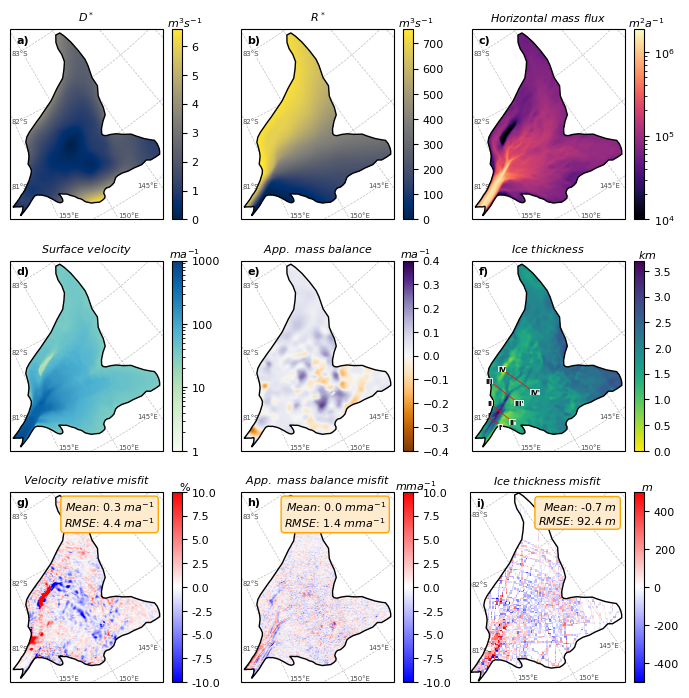

In [ ]:
# all results PENN

fs = 8

# grid the radar lines
xg = np.unique(XH)
yg = np.unique(YH)
ix = np.searchsorted(xg,XH)
iy = np.searchsorted(yg,YH)
Hprofile = np.full((len(yg),len(xg)),np.nan)
Hprofile[iy,ix] = H_crop.reshape([len(H_crop),1])
Hprofile = np.flipud(Hprofile)

fig, ((ax1,ax2,ax3),(ax4,ax5,ax6),(ax7,ax8,ax9)) = plt.subplots(nrows=3,ncols=3,figsize=[17.9*cm,18*cm], subplot_kw={'projection':proj})

data = sio.loadmat(f'{homepath}/saved-data/exp1-No1-potentials-and-mass-flux-Measures-grid.mat')
X = data['x']
Y = data['y']
D = data['D']
R = data['R']
mf = data['MF']

data1 = sio.loadmat(f'{homepath}/saved-data/exp1-ice-thickness-BedMap-grid.mat')
data2 = sio.loadmat(f'{homepath}/saved-data/exp1-apparent-mass-balance-BedMap-grid.mat')
data3 = sio.loadmat(f'{homepath}/saved-data/exp1-surface-velocity-Measures-grid.mat')
Xbm = data1['x']
Ybm = data1['y']
Xsmb = data2['x'][:,0]
Ysmb = data2['y'][:,0]
Xvel = data3['x']
Yvel = data3['y']

xdim = int((np.max(Xsmb)-np.min(Xsmb))/500) + 1
ydim = int((np.max(Ysmb)-np.min(Ysmb))/500) + 1

H = data1['mean_thickness']
smb = data2['mean_app_mb'][0,:]
vel = data3['mean_velocity']

vel_obs = spy*np.sqrt(vxcrop**2 + vycrop**2)
vel_diff = vel-vel_obs.flatten()
smb_diff = smb-spy*smb_crop
H_diff = H - Hprofile.flatten()

vel_drel = vel_diff/vel_obs.flatten()
smb_drel = smb_diff/(spy*smb_crop)
lim = 0.001
smb_drel = np.where(np.logical_or(spy*smb_crop>lim,spy*smb_crop<-lim),smb_drel,np.nan)
H_drel = H_diff/Hprofile.flatten()

# pool the H_diff
n = 5
H_diff_rs = H_diff.reshape((Xbm.shape[0],Xbm.shape[1]))
# H_diff_lr = H_diff_rs.reshape(-1, n, Xbm.shape[0]//n, n).sum((-1, -3)) / n
k, l = H_diff_rs.shape
pad = (-k % n, -l % n)
H_diff_rs_pad = np.pad(H_diff_rs, ((0, pad[0]), (0, pad[1])), constant_values=np.nan)
sign = np.where(H_diff_rs_pad<0,-1,1)
H_diff_lr = H_diff_rs_pad.reshape(H_diff_rs_pad.shape[0] // n, n,
                     H_diff_rs_pad.shape[1] // n, n)
H_diff_lr_pos = np.nanmax(H_diff_lr, axis=(1, 3))
H_diff_lr_min = np.nanmin(H_diff_lr, axis=(1, 3))
H_diff_lr = np.where(np.abs(H_diff_lr_min)>H_diff_lr_pos,H_diff_lr_min,H_diff_lr_pos)

vrel = 0.1 * 100.
norm_rel = TwoSlopeNorm(vmin=-1*vrel, vcenter=0., vmax=vrel)

cmapdiff = 'bwr'


a1 = ax1.pcolormesh(X,Y,D.reshape((Xv.shape[0],Xv.shape[1])),cmap='cividis',shading='gouraud',transform=proj)
a2 = ax2.pcolormesh(X,Y,R.reshape((Xv.shape[0],Xv.shape[1])),cmap='cividis',shading='gouraud',transform=proj)
a3 = ax3.pcolormesh(X,Y,(mf).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap='magma',norm=LogNorm(vmin=1e4),transform=proj)

a4 = ax4.pcolormesh(Xvel,Yvel,(vel).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap='GnBu',norm=LogNorm(vmin=1,vmax=1000),transform=proj)
a5 = ax5.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb.reshape((ydim,xdim)),shading='gouraud',cmap='PuOr',vmin=-0.4,vmax=0.4,transform=proj)#
a6 = ax6.pcolormesh(Xbm,Ybm,H.reshape((Xbm.shape[0],Xbm.shape[1])),shading='gouraud',cmap='viridis_r',vmin=0,vmax=3700,transform=proj)

## absolute differences
# a7 = ax7.pcolormesh(Xvel,Yvel,vel_diff.reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap=cmapdiff,vmax=20,vmin=-20,transform=proj)
a8 = ax8.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb_diff.reshape((ydim,xdim)),cmap=cmapdiff,shading='gouraud',vmin=-0.01,vmax=0.01,transform=proj)
# a9 = ax9.pcolormesh(Xbm,Ybm,H_diff.reshape((Xbm.shape[0],Xbm.shape[1])),cmap=cmapdiff,transform=proj,vmin=-250.,vmax=250.) # 
a9 = ax9.pcolormesh(Xbm[::n,::n],Ybm[::n,::n],H_diff_lr,cmap=cmapdiff,transform=proj,vmin=-500.,vmax=500.) # 
# mask = np.where(~np.isnan(H_diff[0]))
# a9 = ax9.scatter(Xbm.flatten()[mask],Ybm.flatten()[mask],c=H_diff[0][mask],s=0.00001,marker='h',cmap=cmapdiff,vmin=-200.,vmax=200.)#,transform=proj)

## relative differences
a7 = ax7.pcolormesh(Xvel,Yvel,vel_drel.reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap=cmapdiff,vmax=0.1,vmin=-0.1,transform=proj)
# a8 = ax8.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb_drel.reshape((ydim,xdim)),cmap=cmapdiff,shading='gouraud',vmin=-0.1,vmax=0.1,transform=proj)
# a9 = ax9.pcolormesh(Xbm,Ybm,H_drel.reshape((Xbm.shape[0],Xbm.shape[1])),cmap=cmapdiff,vmin=-0.1,vmax=0.1,transform=proj)
# mask = np.where(~np.isnan(H_drel[0]))
# a9 = ax9.scatter(Xbm.flatten()[mask],Ybm.flatten()[mask],c=H_drel[0][mask],s=0.00001,marker='h',cmap=cmapdiff,vmin=-200.,vmax=200.)#,transform=proj)

for ax,a in zip([ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9],[a1, a2, a3, a4, a5, a6, a7, a8, a9]):
    outline = Polygon(vertices, closed=True, fill=False, edgecolor='black')
    ax.add_patch(outline)
    Artist.set_clip_path(a,outline)
    ax.set_aspect(1)

for ax,a in zip([ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9],[a1, a2, a3, a4, a5, a6, a7, a8, a9]):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))

    ax.margins(x=0.02, y=0.02)

    gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=False,      # don't label the outside
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
    )
    gl.zorder = 0
    gl.xlocator = mticker.FixedLocator(range(-180, 181, 5))
    gl.ylocator = mticker.FixedLocator(range(-90, -59, 1))

    # Latitude labels
    for lat,y0 in zip(range(-83, -80, 1),[-687000,-812000,-932000]):
        x0 = 373000+5e3 if ax==ax9 else 373000 
        ax.text(
            x0, y0,
            f"{-1*lat}°S",
            fontsize=fs-3,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            ),
            zorder=0
        )

    # Longitude labels
    for lon,x0,y0 in zip([155,150,145],[460000,570000,605000],[-987000,-987000,-930000]):
        y0 = y0+7e3 if ax==ax9 else y0
        ax.text(
            x0, y0,
            f"{lon}°E",
            fontsize=fs-3,
            color="0.3",
                bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )
    
for ax,a,label in zip([ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9],[a1, a2, a3, a4, a5, a6, a7, a8, a9],['m^3 s^{-1}','m^3 s^{-1}','m^2 a^{-1}','m a^{-1}','m a^{-1}','km','\%','mm a^{-1}','m']):
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.97)
    cbar.ax.tick_params(labelsize=fs)
    cbar.ax.set_title(f'${label}$',fontsize=fs,x=1.3,pad=-0)
    if ax in [ax6]:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.1f}'))
    # absolute differences {
    elif ax in [ax4,ax9]:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}'))
    elif ax in [ax8]:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e3:.1f}')) # }
    # relative difference {
    elif ax in [ax7]:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.1f}')) # }
    # else:
    #     cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1f}'))

for ax,diff,label in zip([ax7,ax8,ax9],[vel_diff,1000*smb_diff,H_diff],['m a^{-1}','mm a^{-1}','m']):
    stats = (f'$Mean$: {np.nanmean(diff):.1f} ${label}$\n'
            f'$RMSE$: {np.sqrt(np.nanmean(np.square(diff))):.1f} ${label}$'
            )
    bbox = dict(boxstyle='round', fc='blanchedalmond', ec='orange', alpha=1)
    ax.text(0.95, 0.96, stats, fontsize=fs, bbox=bbox, transform=ax.transAxes, ha='right', va='top')

# a,b,c
for label,ax in zip(['a','b','c','d','e','f','g','h','i'],[ax1,ax2,ax3,ax4,ax5,ax6,ax7,ax8,ax9]):
    ax.text(
        0.04, 0.97, f'{label})',
        transform=ax.transAxes,
        fontsize=fs,
        fontweight='bold',
        va='top',
        ha='left'
    )


ax1.set_title('$D^*$',fontsize=fs)
ax2.set_title('$R^*$',fontsize=fs)
ax3.set_title('$Horizontal\ mass\ flux$',fontsize=fs)
ax4.set_title('$Surface\ velocity$',fontsize=fs)
ax5.set_title('$App.\ mass\ balance$',fontsize=fs)
ax6.set_title('$Ice\ thickness$',fontsize=fs)
ax7.set_title('$Velocity\ relative\ misfit$',fontsize=fs)
ax8.set_title('$App.\ mass\ balance\ misfit$',fontsize=fs)
ax9.set_title('$Ice\ thickness\ misfit$',fontsize=fs)

letters = ['I\'','I','II\'','II','III','III\'','IV\'','IV']
x_corr = [0,-0.5e4,0,-1.1e4,-1.5e4,0,0,-1.5e4]
y_corr =[0,1.2e4,0,1.2e4,1.2e4,0,0,1.2e4]

for i in np.arange(4):

    data_s = sio.loadmat(f'{homepath}/saved-data/profile-p{i+1}-bmap3-interpolated-surface.mat')
    
    xA = data_s['x'][0]
    xAA = data_s['x'][-1]
    yA = data_s['y'][0]
    yAA = data_s['y'][-1]
    ax6.plot([xA,xAA],[yA,yAA],color='red',linewidth=0.5)

    ax6.text(
        xA+x_corr[i*2],yA+y_corr[i*2], f'{letters[i*2]}',
        # transform=ax1.transAxes,
        fontsize=fs-3,
        fontweight='bold',
        va='top',
        ha='left',
        bbox=dict(
            facecolor="white",
            edgecolor="none",   # or "black"
            alpha=0.8,
            pad=0.)
    )

    ax6.text(
        xAA+x_corr[i*2+1],yAA+y_corr[i*2+1], f'{letters[i*2+1]}',
        # transform=ax1.transAxes,
        fontsize=fs-3,
        fontweight='bold',
        va='top',
        ha='left',
        bbox=dict(
            facecolor="white",
            edgecolor="none",   # or "black"
            alpha=0.8,
            pad=0.)
    )

# plt.show()

fig.tight_layout()

plt.savefig(f'{figurepath}Fig-all-results-PENN-2.jpg',dpi=1200,pad_inches=0.,bbox_inches=None)


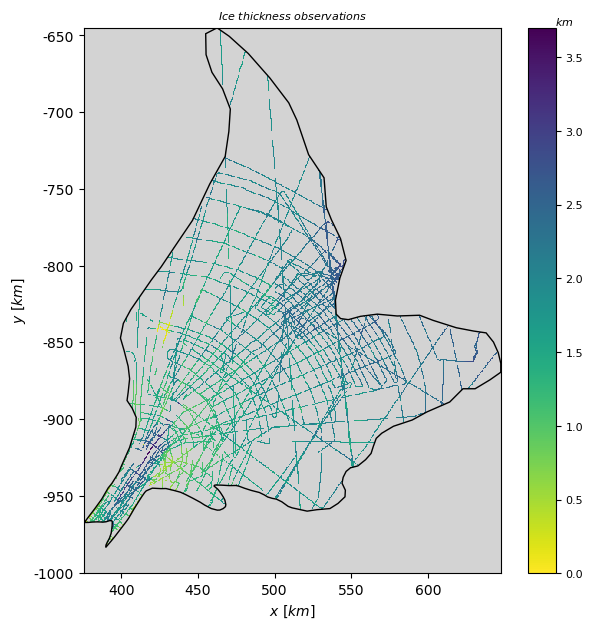

In [33]:
## Suppl. fig, run code in previous cell first
fig, ax = plt.subplots(nrows=1,ncols=1,figsize=[17.9*cm,18*cm])#, subplot_kw={'projection':proj})

ax.set_facecolor("lightgrey") 
a = ax.pcolormesh(Xbm,Ybm,Hprofile,cmap='viridis_r',vmin=0.,vmax=3700.)#,transform=proj)

outline = Polygon(vertices, closed=True, fill=False, edgecolor='black')
ax.add_patch(outline)
Artist.set_clip_path(a,outline)
ax.set_aspect(1)

ax.set_xlabel('$x\ [km]$')
ax.set_ylabel('$y\ [km]$')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))

cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.97)
cbar.ax.tick_params(labelsize=fs)
cbar.ax.set_title(f'$km$',fontsize=fs,x=1.3,pad=-0)
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.1f}'))

ax.set_title('$Ice\ thickness\ observations$',fontsize=fs)
plt.savefig(f'{figurepath}Fig-suppl-thickness-obs.jpg',dpi=1200,pad_inches=0.,bbox_inches=None)

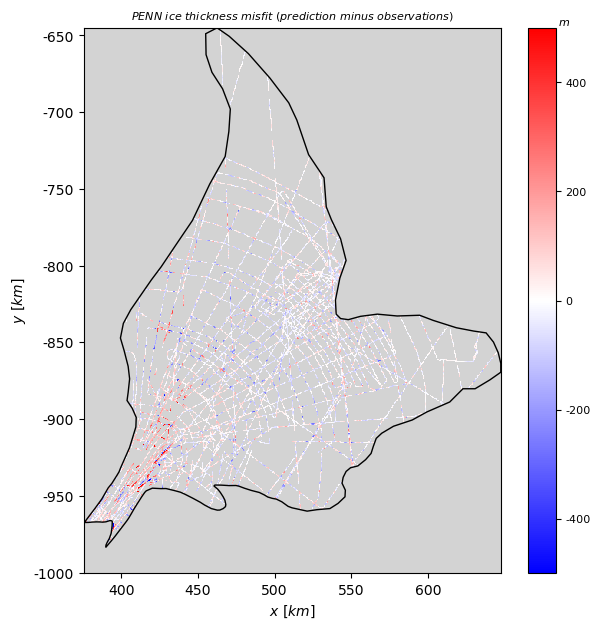

In [63]:
## Suppl. fig, run code in previous cell first
fig, ax = plt.subplots(nrows=1,ncols=1,figsize=[17.9*cm,18*cm])#, subplot_kw={'projection':proj})

ax.set_facecolor("lightgrey") 
a = ax.pcolormesh(Xbm,Ybm,H_diff.reshape((Xbm.shape[0],Xbm.shape[1])),cmap=cmapdiff,vmin=-500.,vmax=500.)#,transform=proj)

outline = Polygon(vertices, closed=True, fill=False, edgecolor='black')
ax.add_patch(outline)
Artist.set_clip_path(a,outline)
ax.set_aspect(1)

ax.set_xlabel('$x\ [km]$')
ax.set_ylabel('$y\ [km]$')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))

cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.97)
cbar.ax.tick_params(labelsize=fs)
cbar.ax.set_title(f'$m$',fontsize=fs,x=1.3,pad=-0)
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}'))

ax.set_title('$PENN\ ice\ thickness\ misfit\ (prediction\ minus\ observations)$',fontsize=fs)
plt.savefig(f'{figurepath}Fig-suppl-PENN-thickness-misfit.jpg',dpi=1200,pad_inches=0.,bbox_inches=None)

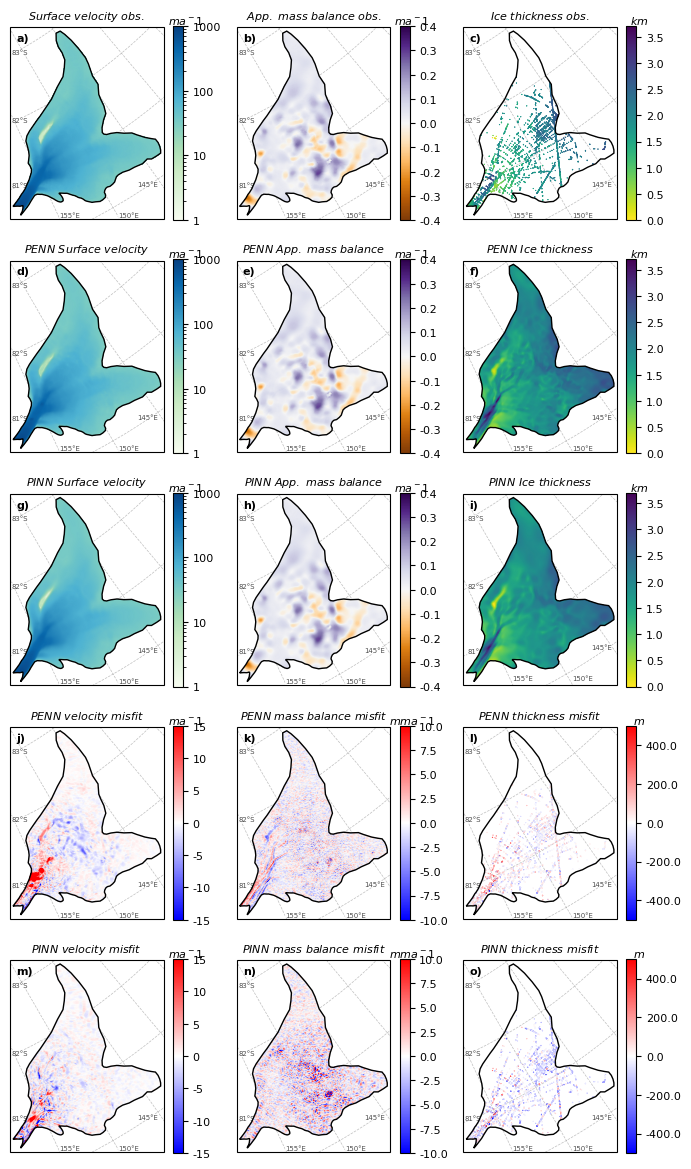

In [ ]:
# suppl. figure, original data

# grid the radar lines
xg = np.unique(XH)
yg = np.unique(YH)
ix = np.searchsorted(xg,XH)
iy = np.searchsorted(yg,YH)
Hprofile = np.full((len(yg),len(xg)),np.nan)
Hprofile[iy,ix] = H_crop.reshape([len(H_crop),1])
Hprofile = np.flipud(Hprofile)

fig, ((ax1,ax2,ax3),(ax4,ax5,ax6),(ax7,ax8,ax9),(ax10,ax11,ax12),(ax13,ax14,ax15)) = plt.subplots(nrows=5,ncols=3,figsize=[17.9*cm,30*cm], subplot_kw={'projection':proj})

# PENN data
data1 = sio.loadmat(f'{homepath}/saved-data/exp1-ice-thickness-BedMap-grid.mat')
data2 = sio.loadmat(f'{homepath}/saved-data/exp1-apparent-mass-balance-BedMap-grid.mat')
data3 = sio.loadmat(f'{homepath}/saved-data/exp1-surface-velocity-Measures-grid.mat')

#PINN data
data4 = sio.loadmat(f'{homepath}/saved-data/exp2-ice-thickness-BedMap-grid.mat')
data5 = sio.loadmat(f'{homepath}/saved-data/exp2-apparent-mass-balance-BedMap-grid.mat')
data6 = sio.loadmat(f'{homepath}/saved-data/exp2-surface-velocity-Measures-grid.mat')

Xbm = data1['x']
Ybm = data1['y']
Xsmb = data2['x'][:,0]
Ysmb = data2['y'][:,0]
Xvel = data3['x']
Yvel = data3['y']

xdim = int((np.max(Xsmb)-np.min(Xsmb))/500) + 1
ydim = int((np.max(Ysmb)-np.min(Ysmb))/500) + 1

H_penn = data1['mean_thickness']
smb_penn = data2['mean_app_mb'][0,:]
vel_penn = data3['mean_velocity']

H_pinn = data4['mean_thickness']
smb_pinn = data5['mean_app_mb'][0,:]
vel_pinn = data6['mean_velocity']

vel_obs = spy*np.sqrt(vxcrop**2 + vycrop**2)

vel_diff_penn = vel_penn-vel_obs.flatten()
smb_diff_penn = smb_penn-spy*smb_crop
H_diff_penn = H_penn - Hprofile.flatten()

vel_diff_pinn = vel_pinn-vel_obs.flatten()
smb_diff_pinn = smb_pinn-spy*smb_crop
H_diff_pinn = H_pinn - Hprofile.flatten()


cmapdiff = 'bwr'


a1 = ax1.pcolormesh(Xvel,Yvel,(vel_obs),shading='gouraud',cmap='GnBu',norm=LogNorm(vmin=1,vmax=1000),transform=proj)
a2 = ax2.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),spy*smb_crop.reshape((ydim,xdim)),shading='gouraud',cmap='PuOr',vmin=-0.4,vmax=0.4,transform=proj)#
a3 = ax3.pcolormesh(Xbm,Ybm,Hprofile,shading='gouraud',cmap='viridis_r',vmin=0,vmax=3700,transform=proj)

a4 = ax4.pcolormesh(Xvel,Yvel,(vel_penn).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap='GnBu',norm=LogNorm(vmin=1,vmax=1000),transform=proj)
a5 = ax5.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb_penn.reshape((ydim,xdim)),shading='gouraud',cmap='PuOr',vmin=-0.4,vmax=0.4,transform=proj)#
a6 = ax6.pcolormesh(Xbm,Ybm,H_penn.reshape((Xbm.shape[0],Xbm.shape[1])),shading='gouraud',cmap='viridis_r',vmin=0,vmax=3700,transform=proj)

a7 = ax7.pcolormesh(Xvel,Yvel,(vel_pinn).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap='GnBu',norm=LogNorm(vmin=1,vmax=1000),transform=proj)
a8 = ax8.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb_pinn.reshape((ydim,xdim)),shading='gouraud',cmap='PuOr',vmin=-0.4,vmax=0.4,transform=proj)#
a9 = ax9.pcolormesh(Xbm,Ybm,H_pinn.reshape((Xbm.shape[0],Xbm.shape[1])),shading='gouraud',cmap='viridis_r',vmin=0,vmax=3700,transform=proj)

a10 = ax10.pcolormesh(Xvel,Yvel,(vel_diff_penn).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap=cmapdiff,vmin=-15,vmax=15,transform=proj)
a11 = ax11.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb_diff_penn.reshape((ydim,xdim)),shading='gouraud',cmap=cmapdiff,vmin=-0.01,vmax=0.01,transform=proj)#
a12 = ax12.pcolormesh(Xbm,Ybm,H_diff_penn.reshape((Xbm.shape[0],Xbm.shape[1])),shading='gouraud',cmap=cmapdiff,vmin=-500,vmax=500,transform=proj)

a13 = ax13.pcolormesh(Xvel,Yvel,(vel_diff_pinn).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap=cmapdiff,vmin=-15,vmax=15,transform=proj)
a14 = ax14.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb_diff_pinn.reshape((ydim,xdim)),shading='gouraud',cmap=cmapdiff,vmin=-0.01,vmax=0.01,transform=proj)#
a15 = ax15.pcolormesh(Xbm,Ybm,H_diff_pinn.reshape((Xbm.shape[0],Xbm.shape[1])),shading='gouraud',cmap=cmapdiff,vmin=-500,vmax=500,transform=proj)


for ax,a in zip([ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9, ax10,ax11,ax12,ax13,ax14,ax15],[a1, a2, a3, a4, a5, a6, a7, a8, a9,a10,a11,a12,a13,a14,a15]):
    outline = Polygon(vertices, closed=True, fill=False, edgecolor='black')
    ax.add_patch(outline)
    Artist.set_clip_path(a,outline)
    ax.set_aspect(1)

for ax,a in zip([ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9, ax10,ax11,ax12,ax13,ax14,ax15],[a1, a2, a3, a4, a5, a6, a7, a8, a9,a10,a11,a12,a13,a14,a15]):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))

    ax.margins(x=0.02, y=0.02)

    gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=False,      # don't label the outside
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
    )
    gl.zorder = 0
    gl.xlocator = mticker.FixedLocator(range(-180, 181, 5))
    gl.ylocator = mticker.FixedLocator(range(-90, -59, 1))

    # Latitude labels
    for lat,y0 in zip(range(-83, -80, 1),[-687000,-812000,-932000]):
        x0 = 373000+5e3 if ax==ax9 else 373000 
        ax.text(
            x0, y0,
            f"{-1*lat}°S",
            fontsize=fs-3,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            ),
            zorder=0
        )

    # Longitude labels
    for lon,x0,y0 in zip([155,150,145],[460000,570000,605000],[-987000,-987000,-930000]):
        y0 = y0+7e3 if ax==ax9 else y0
        ax.text(
            x0, y0,
            f"{lon}°E",
            fontsize=fs-3,
            color="0.3",
                bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )
    
for ax,a in zip([ax1, ax4, ax7, ax10, ax13],[a1, a4, a7, a10, a13]):
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.97)
    cbar.ax.tick_params(labelsize=fs)
    cbar.ax.set_title(f'$m a^{-1}$',fontsize=fs,x=1.3,pad=-0)
    cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}'))

for ax,a in zip([ax2, ax5, ax8, ax11, ax14],[a2, a5, a8, a11, a14]):
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.97)
    cbar.ax.tick_params(labelsize=fs)
    if ax in [ax11,ax14]:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e3:.1f}'))
        cbar.ax.set_title(f'$mm a^{-1}$',fontsize=fs,x=1.3,pad=-0)
    else:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1f}'))
        cbar.ax.set_title(f'$m a^{-1}$',fontsize=fs,x=1.3,pad=-0)

for ax,a in zip([ax3, ax6, ax9, ax12, ax15],[a3, a6, a9, a12, a15]):
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.97)
    cbar.ax.tick_params(labelsize=fs)
    if ax in [ax12,ax15]:
        cbar.ax.set_title(f'$m$',fontsize=fs,x=1.3,pad=-0)
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1f}'))
    else:
        cbar.ax.set_title(f'$km$',fontsize=fs,x=1.3,pad=-0)
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.1f}'))



# a,b,c
for label,ax in zip(['a','b','c','d','e','f','g','h','i','j','k','l','m','n','o'],[ax1,ax2,ax3,ax4,ax5,ax6,ax7,ax8,ax9,ax10,ax11,ax12,ax13,ax14,ax15]):
    ax.text(
        0.04, 0.97, f'{label})',
        transform=ax.transAxes,
        fontsize=fs,
        fontweight='bold',
        va='top',
        ha='left'
    )

ax1.set_title('$Surface\ velocity\ obs.$',fontsize=fs)
ax2.set_title('$App.\ mass\ balance\ obs.$',fontsize=fs)
ax3.set_title('$Ice\ thickness\ obs.$',fontsize=fs)

ax4.set_title('$PENN\ Surface\ velocity$',fontsize=fs)
ax5.set_title('$PENN\ App.\ mass\ balance$',fontsize=fs)
ax6.set_title('$PENN\ Ice\ thickness$',fontsize=fs)

ax7.set_title('$PINN\ Surface\ velocity$',fontsize=fs)
ax8.set_title('$PINN\ App.\ mass\ balance$',fontsize=fs)
ax9.set_title('$PINN\ Ice\ thickness$',fontsize=fs)

ax10.set_title('$PENN\ velocity\ misfit$',fontsize=fs)
ax11.set_title('$PENN\ mass\ balance\ misfit$',fontsize=fs)
ax12.set_title('$PENN\ thickness\ misfit$',fontsize=fs)

ax13.set_title('$PINN\ velocity\ misfit$',fontsize=fs)
ax14.set_title('$PINN\ mass\ balance\ misfit$',fontsize=fs)
ax15.set_title('$PINN\ thickness\ misfit$',fontsize=fs)

# plt.show()

fig.tight_layout()

plt.savefig(f'{figurepath}Fig-suppl-original-data.jpg',dpi=1200,pad_inches=0.,bbox_inches=None)


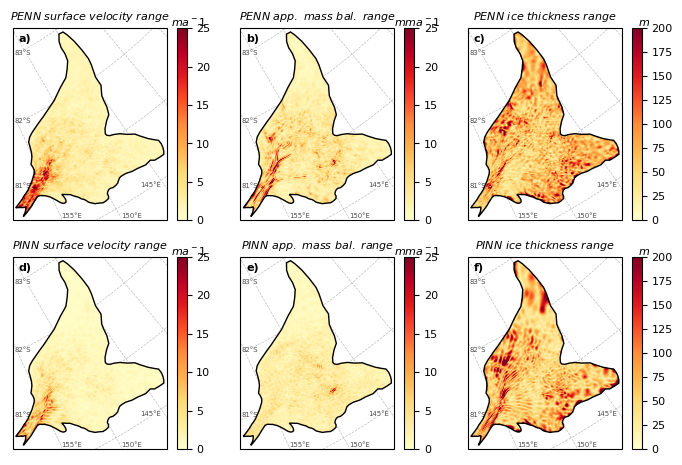

In [ ]:
# suppl. figure, variablility

# grid the radar lines
xg = np.unique(XH)
yg = np.unique(YH)
ix = np.searchsorted(xg,XH)
iy = np.searchsorted(yg,YH)
Hprofile = np.full((len(yg),len(xg)),np.nan)
Hprofile[iy,ix] = H_crop.reshape([len(H_crop),1])
Hprofile = np.flipud(Hprofile)

fig, ((ax1,ax2,ax3),(ax4,ax5,ax6)) = plt.subplots(nrows=2,ncols=3,figsize=[17.9*cm,12*cm], subplot_kw={'projection':proj})

# PENN data
data1 = sio.loadmat(f'{homepath}/saved-data/exp1-ice-thickness-BedMap-grid.mat')
data2 = sio.loadmat(f'{homepath}/saved-data/exp1-apparent-mass-balance-BedMap-grid.mat')
data3 = sio.loadmat(f'{homepath}/saved-data/exp1-surface-velocity-Measures-grid.mat')

#PINN data
data4 = sio.loadmat(f'{homepath}/saved-data/exp2-ice-thickness-BedMap-grid.mat')
data5 = sio.loadmat(f'{homepath}/saved-data/exp2-apparent-mass-balance-BedMap-grid.mat')
data6 = sio.loadmat(f'{homepath}/saved-data/exp2-surface-velocity-Measures-grid.mat')

Xbm = data1['x']
Ybm = data1['y']
Xsmb = data2['x'][:,0]
Ysmb = data2['y'][:,0]
Xvel = data3['x']
Yvel = data3['y']

H_range_penn = data1['min_max_range']
smb_range_penn = data2['min_max_range'][0,:]
vel_range_penn = data3['min_max_range']

H_range_pinn = data4['min_max_range']
smb_range_pinn = data5['min_max_range'][0,:]
vel_range_pinn = data6['min_max_range']


cmap = 'YlOrRd' # 'seismic'


a1 = ax1.pcolormesh(Xvel,Yvel,(vel_range_penn).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap=cmap,vmin=0,vmax=25,transform=proj)#
a2 = ax2.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb_range_penn.reshape((ydim,xdim)),shading='gouraud',cmap=cmap,vmin=0,vmax=0.025,transform=proj)#
a3 = ax3.pcolormesh(Xbm,Ybm,H_range_penn.reshape((Xbm.shape[0],Xbm.shape[1])),shading='gouraud',cmap=cmap,vmin=0,vmax=200,transform=proj)#

a4 = ax4.pcolormesh(Xvel,Yvel,(vel_range_pinn).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap=cmap,vmin=0,vmax=25,transform=proj)#
a5 = ax5.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb_range_pinn.reshape((ydim,xdim)),shading='gouraud',cmap=cmap,vmin=0,vmax=0.025,transform=proj)#
a6 = ax6.pcolormesh(Xbm,Ybm,H_range_pinn.reshape((Xbm.shape[0],Xbm.shape[1])),shading='gouraud',cmap=cmap,vmin=0,vmax=200,transform=proj)#


for ax,a in zip([ax1, ax2, ax3, ax4, ax5, ax6],[a1, a2, a3, a4, a5, a6]):
    outline = Polygon(vertices, closed=True, fill=False, edgecolor='black')
    ax.add_patch(outline)
    Artist.set_clip_path(a,outline)
    ax.set_aspect(1)

for ax,a in zip([ax1, ax2, ax3, ax4, ax5, ax6],[a1, a2, a3, a4, a5, a6]):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))

    ax.margins(x=0.02, y=0.02)

    gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=False,      # don't label the outside
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
    )
    gl.zorder = 0
    gl.xlocator = mticker.FixedLocator(range(-180, 181, 5))
    gl.ylocator = mticker.FixedLocator(range(-90, -59, 1))

    # Latitude labels
    for lat,y0 in zip(range(-83, -80, 1),[-687000,-812000,-932000]):
        x0 = 373000+5e3 if ax==ax9 else 373000 
        ax.text(
            x0, y0,
            f"{-1*lat}°S",
            fontsize=fs-3,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            ),
            zorder=0
        )

    # Longitude labels
    for lon,x0,y0 in zip([155,150,145],[460000,570000,605000],[-987000,-987000,-930000]):
        y0 = y0+7e3 if ax==ax9 else y0
        ax.text(
            x0, y0,
            f"{lon}°E",
            fontsize=fs-3,
            color="0.3",
                bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )
    
for ax,a in zip([ax1, ax4],[a1, a4]):
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.97)
    cbar.ax.tick_params(labelsize=fs)
    cbar.ax.set_title(f'$m a^{-1}$',fontsize=fs,x=1.3,pad=-0)
    cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}'))

for ax,a in zip([ax2, ax5],[a2, a5]):
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.97)
    cbar.ax.tick_params(labelsize=fs)
    cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e3:.0f}'))
    cbar.ax.set_title(f'$mm a^{-1}$',fontsize=fs,x=1.3,pad=-0)

for ax,a in zip([ax3, ax6],[a3, a6]):
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.97)
    cbar.ax.tick_params(labelsize=fs)
    cbar.ax.set_title(f'$m$',fontsize=fs,x=1.3,pad=-0)
    cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}'))



# a,b,c
for label,ax in zip(['a','b','c','d','e','f'],[ax1,ax2,ax3,ax4,ax5,ax6]):
    ax.text(
        0.04, 0.97, f'{label})',
        transform=ax.transAxes,
        fontsize=fs,
        fontweight='bold',
        va='top',
        ha='left'
    )

ax1.set_title('$PENN\ surface\ velocity\ range$',fontsize=fs)
ax2.set_title('$PENN\ app.\ mass\ bal.\ range$',fontsize=fs)
ax3.set_title('$PENN\ ice\ thickness\ range$',fontsize=fs)

ax4.set_title('$PINN\ surface\ velocity\ range$',fontsize=fs)
ax5.set_title('$PINN\ app.\ mass\ bal.\ range$',fontsize=fs)
ax6.set_title('$PINN\ ice\ thickness\ range$',fontsize=fs)

fig.tight_layout()

plt.savefig(f'{figurepath}Fig-suppl-minmax-range.jpg',dpi=900,pad_inches=0.,bbox_inches=None)


In [ ]:
# prepare data for Comparison to BedMachine
# need to run before next cell
# runtime ca. 17 min

data = sio.loadmat(f'{homepath}/saved-data/exp1-ice-thickness-BedMachine-grid.mat')
H_p = data['mean_thickness']
b_p = s2crop.flatten() - H_p
bmbed = np.where(inside_s,bedcrop.flatten(),np.nan)
b_diff = b_p - bmbed

######

x = ds_H['x']
y = ds_H['y']

x = np.transpose(x)
y = np.transpose(y)

xy = np.hstack((x,y))

radar_H = ds_H['median-thickness']

poly_path = Path(vertices)
inside_s = poly_path.contains_points(XYs)
inside_radar = poly_path.contains_points(xy)

in_x = np.where(inside_radar,x.flatten(),np.nan)
in_y = np.where(inside_radar,y.flatten(),np.nan)
in_radar = np.where(inside_radar,radar_H.flatten(),np.nan)

pred_int = griddata(XYs,H_p.flatten(),(in_x,in_y),method='linear')
pred_bm = griddata(XYs,bcrop.flatten(),(in_x,in_y),method='linear')

/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_78051/234959733.py:31: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect1,conn1 = ax1.indicate_inset_zoom(axins1, edgecolor="black")
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_78051/234959733.py:32: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect2,conn2 = ax1.indicate_inset_zoom(axins2, edgecolor="black")
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_78051/234959733.py:48: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist w

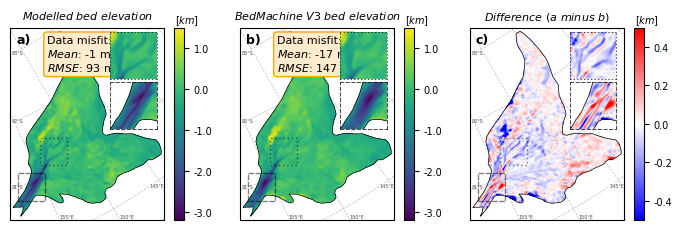

In [ ]:
# Comparison to BedMachine
# run previous cell first

fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=[17.9*cm,6*cm],subplot_kw={"projection": proj})

vmin = -3200.
vmax = 1500.
vbound = 500

cmapTerrain = 'viridis' # 'terrain' # 'gist_earth' # 'copper' # 
normTerrain = mcolors.Normalize(vmin=vmin,vmax=vmax)
cmapdiff = 'bwr' # 'coolwarm' # 'seismic' # 

a1 = ax1.pcolormesh(Xs,Ys,b_p.reshape((Xs.shape[0],Xs.shape[1])),cmap=cmapTerrain,shading='gouraud',norm=normTerrain,transform=proj)
a2 = ax2.pcolormesh(Xs,Ys,bmbed.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapTerrain,norm=normTerrain,transform=proj)
a3 = ax3.pcolormesh(Xs,Ys,b_diff.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapdiff,vmin=-1*vbound,vmax=vbound,transform=proj)

x1, x2, y1, y2 = 3.85e5, 4.35e5, -9.55e5, -9.05e5  # subregion of the original image
axins1 = ax1.inset_axes(
    [0.65, 0.36, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai1 = axins1.pcolormesh(Xs,Ys,b_p.reshape((Xs.shape[0],Xs.shape[1])),cmap=cmapTerrain,shading='gouraud',norm=normTerrain)
axins1.set_aspect(1)

x1, x2, y1, y2 = 4.25e5, 4.75e5, -8.9e5, -8.4e5  # subregion of the original image
axins2 = ax1.inset_axes(
    [0.65, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai2 = axins2.pcolormesh(Xs,Ys,b_p.reshape((Xs.shape[0],Xs.shape[1])),cmap=cmapTerrain,shading='gouraud',norm=normTerrain)
axins1.set_aspect(1)

rect1,conn1 = ax1.indicate_inset_zoom(axins1, edgecolor="black")
rect2,conn2 = ax1.indicate_inset_zoom(axins2, edgecolor="black")

x1, x2, y1, y2 = 3.85e5, 4.35e5, -9.55e5, -9.05e5  # subregion of the original image
axins3 = ax2.inset_axes(
    [0.65, 0.36, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai3 = axins3.pcolormesh(Xs,Ys,bmbed.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapTerrain,norm=normTerrain)
axins3.set_aspect(1)

x1, x2, y1, y2 = 4.25e5, 4.75e5, -8.9e5, -8.4e5  # subregion of the original image
axins4 = ax2.inset_axes(
    [0.65, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai4 = axins4.pcolormesh(Xs,Ys,bmbed.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapTerrain,norm=normTerrain)
axins4.set_aspect(1)

rect3,conn3 = ax2.indicate_inset_zoom(axins3, edgecolor="black")
rect4,conn4 = ax2.indicate_inset_zoom(axins4, edgecolor="black")

x1, x2, y1, y2 = 3.85e5, 4.35e5, -9.55e5, -9.05e5  # subregion of the original image
axins5 = ax3.inset_axes(
    [0.65, 0.36, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai5 = axins5.pcolormesh(Xs,Ys,b_diff.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapdiff,vmin=-1*vbound,vmax=vbound)
axins5.set_aspect(1)

x1, x2, y1, y2 = 4.25e5, 4.75e5, -8.9e5, -8.4e5  # subregion of the original image
axins6 = ax3.inset_axes(
    [0.65, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai6 = axins6.pcolormesh(Xs,Ys,b_diff.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapdiff,vmin=-1*vbound,vmax=vbound)
axins6.set_aspect(1)

rect5,conn5 = ax3.indicate_inset_zoom(axins3, edgecolor="black")
rect6,conn6 = ax3.indicate_inset_zoom(axins4, edgecolor="black")

for conn in [conn1,conn2,conn3,conn4,conn5,conn6]:
    for c in conn:
        c.set_visible(False)

for axin in [axins1,axins2,axins3,axins4,axins5,axins6]:
    axin.set_xticks([])
    axin.set_yticks([])

for ax,a in zip([ax1, ax2, ax3, axins1, axins3, axins5, axins2, axins4, axins6],[a1, a2, a3, ai1, ai3, ai5, ai2, ai4, ai6]):
    outline = Polygon(vertices, closed=True, fill=False, edgecolor='black',linewidth=0.5)
    ax.add_patch(outline)

    Artist.set_clip_path(a,outline)
    ax.set_aspect(1)

for ax,a in zip([ax1, ax2, ax3],[a1, a2, a3]):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))

    ax.margins(x=0.02, y=0.02)

    gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=False,      # don't label the outside
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
    )
    gl.zorder = 0
    gl.xlocator = mticker.FixedLocator(range(-180, 181, 5))
    gl.ylocator = mticker.FixedLocator(range(-90, -59, 1))

    # Latitude labels
    for lat,y0 in zip(range(-83, -80, 1),[-687000,-812000,-932000]):
        ax.text(
            373000, y0,
            f"{-1*lat}°S",
            fontsize=3.5,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )

    # Longitude labels
    for lon,x0,y0 in zip([155,150,145],[460000,570000,625000],[-987000,-987000,-930000]):
        ax.text(
            x0, y0,
            f"{lon}°E",
            fontsize=3.5,
            color="0.3",
                bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )
    
    
for ax,a in zip([ax1, ax2, ax3],[a1, a2, a3]):
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.467)
    cbar.ax.tick_params(labelsize=fs-1)
    cbar.ax.set_title('$[km]$',fontsize=fs-1,x=1.3,pad=-0)
    # if a in [a3]:
    cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.1f}'))
    # else:    
    #     cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
    

for axin in [axins1,axins3,axins5]:
    for spine in axin.spines.values():
        # spine.set_edgecolor('red')
        # spine.set_linestyle((0,(1,4)))
        spine.set_linestyle((0,(5,3)))
        spine.set_linewidth(0.5)

for axin in [axins2,axins4,axins6]:
    for spine in axin.spines.values():
        # spine.set_edgecolor('cyan')
        # spine.set_linestyle((0,(5,3)))
        spine.set_linestyle((0,(1,4)))
        spine.set_linewidth(0.5)

for rect in [rect1,rect3,rect5]:
    # rect.set_linestyle((0,(1,2)))
    rect.set_linestyle((0,(4,1)))
    rect.set_linewidth(1)
    rect.set_edgecolor('black')
    rect.set_alpha(0.5)

for rect in [rect2,rect4,rect6]:
    # rect.set_linestyle((0,(4,1)))
    rect.set_linestyle((0,(1,2)))
    rect.set_linewidth(1)
    rect.set_edgecolor('black')
    rect.set_alpha(0.5)

# fig.suptitle('$Ice\ sheet\ bed\ elevation$')
ax1.set_title('$Modelled\ bed\ elevation$',fontsize=fs)
ax2.set_title('$BedMachine\ V3\ bed\ elevation$',fontsize=fs)
ax3.set_title('$Difference\ (a\ minus\ b)$',fontsize=fs)

ax2.set(yticklabels=[])
ax3.set(yticklabels=[])

for ax,diff in zip([ax1,ax2],[diff_pred,diff_bm]):
    stats = ('Data misfit:\n'
            f'$Mean$: {np.nanmean(diff):.0f} m\n'
            f'$RMSE$: {np.sqrt(np.nanmean(np.square(diff))):.0f} m'
            # f'$MAE$: {np.nanmean(np.abs(diff)):.0f}'
            )
    bbox = dict(boxstyle='round', fc='blanchedalmond', ec='orange', alpha=1)
    ax.text(0.24, 0.96, stats, fontsize=fs, bbox=bbox, transform=ax.transAxes, ha='left', va='top')

# a,b,c
for label,ax in zip(['a','b','c'],[ax1,ax2,ax3]):
    ax.text(
        0.04, 0.97, f'{label})',
        transform=ax.transAxes,
        fontsize=fs+1,
        fontweight='bold',
        va='top',
        ha='left'
    )

fig.tight_layout()

plt.savefig(f'{figurepath}Fig-comparison-BedMachine.jpg',dpi=600,pad_inches=0.,bbox_inches=None)


/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_78051/116308644.py:79: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect1,conn1 = ax1.indicate_inset_zoom(axins1, edgecolor="black")
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_78051/116308644.py:80: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect2,conn2 = ax1.indicate_inset_zoom(axins2, edgecolor="black")
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_78051/116308644.py:81: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist w

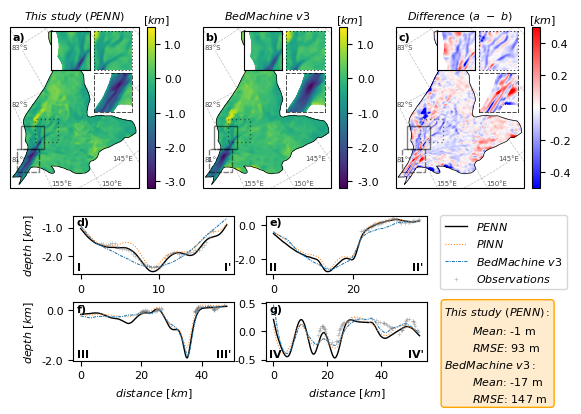

In [ ]:
# bed topography and profiles combined figure

### run "Prepare data for comparison to BedMachine" first

fig = plt.figure(figsize=(17.9*cm, 11*cm))
gs = fig.add_gridspec(3, 3, hspace=0.3, height_ratios=[1.1,0.4,0.4], width_ratios=[1,1,1]) # wspace=0.1, 

ax1 = fig.add_subplot(gs[0,0],projection=proj)
ax2 = fig.add_subplot(gs[0,1],projection=proj)
ax3 = fig.add_subplot(gs[0,2],projection=proj)
ax4 = fig.add_subplot(gs[1, 0])  
ax5 = fig.add_subplot(gs[1, 1])
# ax6 = fig.add_subplot(gs[1:2, 2])
ax7 = fig.add_subplot(gs[2, 0])
ax8 = fig.add_subplot(gs[2, 1])
# ax9 = fig.add_subplot(gs[2, 2])


vmin = -3200.
vmax = 1500.
vbound = 500

cmapTerrain = 'viridis' # 'terrain' # 'gist_earth' # 'copper' # 
normTerrain = mcolors.Normalize(vmin=vmin,vmax=vmax)
cmapdiff = 'bwr' # 'coolwarm' # 'seismic' # 

a1 = ax1.pcolormesh(Xs,Ys,b_p.reshape((Xs.shape[0],Xs.shape[1])),cmap=cmapTerrain,shading='gouraud',norm=normTerrain,transform=proj)
a2 = ax2.pcolormesh(Xs,Ys,bmbed.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapTerrain,norm=normTerrain,transform=proj)
a3 = ax3.pcolormesh(Xs,Ys,b_diff.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapdiff,vmin=-1*vbound,vmax=vbound,transform=proj)

x1, x2, y1, y2 = 3.85e5, 4.35e5, -9.55e5, -9.05e5  # subregion of the original image
axins1 = ax1.inset_axes(
    [0.65, 0.36, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai1 = axins1.pcolormesh(Xs,Ys,b_p.reshape((Xs.shape[0],Xs.shape[1])),cmap=cmapTerrain,shading='gouraud',norm=normTerrain)
axins1.set_aspect(1)

x1, x2, y1, y2 = 4.25e5, 4.75e5, -8.9e5, -8.4e5  # subregion of the original image
axins2 = ax1.inset_axes(
    [0.65, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai2 = axins2.pcolormesh(Xs,Ys,b_p.reshape((Xs.shape[0],Xs.shape[1])),cmap=cmapTerrain,shading='gouraud',norm=normTerrain)
axins2.set_aspect(1)

x1, x2, y1, y2 = 3.95e5, 4.45e5, -9.05e5, -8.55e5  # subregion of the original image
axins3 = ax1.inset_axes(
    [0.32, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai3 = axins3.pcolormesh(Xs,Ys,b_p.reshape((Xs.shape[0],Xs.shape[1])),cmap=cmapTerrain,shading='gouraud',norm=normTerrain)
axins3.set_aspect(1)

rect1,conn1 = ax1.indicate_inset_zoom(axins1, edgecolor="black")
rect2,conn2 = ax1.indicate_inset_zoom(axins2, edgecolor="black")
rect3,conn3 = ax1.indicate_inset_zoom(axins3, edgecolor="black")

x1, x2, y1, y2 = 3.85e5, 4.35e5, -9.55e5, -9.05e5  # subregion of the original image
axins4 = ax2.inset_axes(
    [0.65, 0.36, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai4 = axins4.pcolormesh(Xs,Ys,bmbed.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapTerrain,norm=normTerrain)
axins4.set_aspect(1)

x1, x2, y1, y2 = 4.25e5, 4.75e5, -8.9e5, -8.4e5  # subregion of the original image
axins5 = ax2.inset_axes(
    [0.65, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai5 = axins5.pcolormesh(Xs,Ys,bmbed.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapTerrain,norm=normTerrain)
axins5.set_aspect(1)

x1, x2, y1, y2 = 3.95e5, 4.45e5, -9.05e5, -8.55e5  # subregion of the original image
axins6 = ax2.inset_axes(
    [0.32, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai6 = axins6.pcolormesh(Xs,Ys,bmbed.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapTerrain,norm=normTerrain)
axins6.set_aspect(1)

rect4,conn4 = ax2.indicate_inset_zoom(axins4, edgecolor="black")
rect5,conn5 = ax2.indicate_inset_zoom(axins5, edgecolor="black")
rect6,conn6 = ax2.indicate_inset_zoom(axins6, edgecolor="black")

x1, x2, y1, y2 = 3.85e5, 4.35e5, -9.55e5, -9.05e5  # subregion of the original image
axins7 = ax3.inset_axes(
    [0.65, 0.36, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai7 = axins7.pcolormesh(Xs,Ys,b_diff.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapdiff,vmin=-1*vbound,vmax=vbound)
axins7.set_aspect(1)

x1, x2, y1, y2 = 4.25e5, 4.75e5, -8.9e5, -8.4e5  # subregion of the original image
axins8 = ax3.inset_axes(
    [0.65, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai8 = axins8.pcolormesh(Xs,Ys,b_diff.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapdiff,vmin=-1*vbound,vmax=vbound)
axins8.set_aspect(1)

x1, x2, y1, y2 = 3.95e5, 4.45e5, -9.05e5, -8.55e5  # subregion of the original image
axins9 = ax3.inset_axes(
    [0.32, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai9 = axins9.pcolormesh(Xs,Ys,b_diff.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapdiff,vmin=-1*vbound,vmax=vbound)
axins9.set_aspect(1)

rect7,conn7 = ax3.indicate_inset_zoom(axins7, edgecolor="black")
rect8,conn8 = ax3.indicate_inset_zoom(axins8, edgecolor="black")
rect9,conn9 = ax3.indicate_inset_zoom(axins9, edgecolor="black")

for conn in [conn1,conn2,conn3,conn4,conn5,conn6,conn7,conn8,conn9]:
    for c in conn:
        c.set_visible(False)

for axin in [axins1,axins2,axins3,axins4,axins5,axins6,axins7,axins8,axins9]:
    axin.set_xticks([])
    axin.set_yticks([])

for axin in [axins1,axins4,axins7]:
    for spine in axin.spines.values():
        # spine.set_edgecolor('red')
        # spine.set_linestyle((0,(1,4)))
        spine.set_linestyle((0,(5,3)))
        spine.set_linewidth(0.5)

for axin in [axins2,axins5,axins8]:
    for spine in axin.spines.values():
        # spine.set_edgecolor('cyan')
        # spine.set_linestyle((0,(5,3)))
        spine.set_linestyle((0,(1,4)))
        spine.set_linewidth(0.5)

for rect in [rect1,rect4,rect7]:
    # rect.set_linestyle((0,(1,2)))
    rect.set_linestyle((0,(4,1)))
    rect.set_linewidth(1)
    rect.set_edgecolor('black')
    rect.set_alpha(0.5)

for rect in [rect2,rect5,rect8]:
    # rect.set_linestyle((0,(4,1)))
    rect.set_linestyle((0,(1,2)))
    rect.set_linewidth(1)
    rect.set_edgecolor('black')
    rect.set_alpha(0.5)


for ax,a in zip([ax1,ax2,ax3],[a1,a2,a3]):
    outline = Polygon(vertices, closed=True, fill=False, edgecolor='black',linewidth=0.5)
    ax.add_patch(outline)

    Artist.set_clip_path(a,outline)
    ax.set_aspect(1)

for ax,a in zip([ax1,ax2,ax3],[a1,a2,a3]):
    
    ax.margins(x=0.02, y=0.02)

    gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=False,      # don't label the outside
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
    )
    gl.zorder = 0
    gl.xlocator = mticker.FixedLocator(range(-180, 181, 5))
    gl.ylocator = mticker.FixedLocator(range(-90, -59, 1))

    # Latitude labels
    for lat,y0 in zip(range(-83, -80, 1),[-687000,-812000,-932000]):
        ax.text(
            373000, y0,
            f"{-1*lat}°S",
            fontsize=fs-3,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            ),
            zorder=0
        )

    # Longitude labels
    for lon,x0,y0 in zip([155,150,145],[460000,570000,595000],[-985000,-985000,-930000]):
        ax.text(
            x0, y0,
            f"{lon}°E",
            fontsize=fs-3,
            color="0.3",
                bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )

    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.467)
    cbar.ax.tick_params(labelsize=fs)
    cbar.ax.set_title('$[km]$',fontsize=fs,x=1.3,pad=-0)
    cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.1f}'))


# plot the profiles

for ax,i in zip([ax4,ax5,ax7,ax8],np.arange(4)):

    data_s = sio.loadmat(f'{homepath}/saved-data/profile-p{i+1}-bmap3-interpolated-surface.mat')
    s = data_s['interpolated_surface']



    for name,label,style,color,lw in zip(['exp1','exp2'],['$PENN$','$PINN$'],['solid','dotted'],['k','tab:orange'],[1,0.75]):
        data_p = sio.loadmat(f'{homepath}/saved-data/profile-p{i+1}-{name}-ice-thickness.mat')

        dist = ((data_p['x']-data_p['x'][0])**2 + (data_p['y']-data_p['y'][0])**2)**0.5
        
        bed = s - data_p['mean_thickness']
        if i==2:
            bed=np.flip(bed)

        ax.plot(dist*1e-3,np.flip(bed),label=label,linestyle=style,linewidth=lw,color=color)

    
    for name,label,style,color in zip(['bm3'],['$BedMachine\ v3$'],[(0, (3, 1, 1, 1))],['tab:blue']):
        data_p = sio.loadmat(f'{homepath}/saved-data/profile-p{i+1}-{name}-interpolated-thickness.mat')

        dist = ((data_p['x']-data_p['x'][0])**2 + (data_p['y']-data_p['y'][0])**2)**0.5
        
        bed = data_p['interpolated_thickness']
        if i==2:
            bed=np.flip(bed)

        ax.plot(dist*1e-3,np.flip(bed),label=label,linestyle=style,linewidth=0.75,color=color)

    data_p = sio.loadmat(f'{homepath}/saved-data/profile-p{i+1}-bmap3-ice-thickness-observations.mat')

    dist = ((data_p['x']-data_p['x'][0])**2 + (data_p['y']-data_p['y'][0])**2)**0.5
    
    thk = data_p['thickness']
    thk = np.where(thk<-9000,np.nan,thk)

    bed = s - thk
    if i==2:
        bed=np.flip(bed)

    step = [10,15,2,10]

    ax.plot(dist[::step[i]]*1e-3,np.flip(bed[::step[i]]),label='$Observations$',color='grey',marker='+',markersize=3,markeredgewidth=0.5,alpha=0.5,linestyle='None')


for ax in [ax4,ax7]:
    ax.set_ylabel('$depth\ [km]$',fontsize=fs)

for ax in [ax7,ax8]:
    ax.set_xlabel('$distance\ [km]$',fontsize=fs)


for ax in [ax4,ax5,ax7,ax8]:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.1f}'))
    ax.tick_params(labelsize=fs)
    

# a,b,c
for label,ax in zip(['a','b','c','d','e','f','g'],[ax1,ax2,ax3,ax4,ax5,ax7,ax8]):
    ax.text(
        0.02, 0.97, f'{label})',
        transform=ax.transAxes,
        fontsize=fs,
        fontweight='bold',
        va='top',
        ha='left'
    )

# AA,BB
for l,ax in zip(['I','II','III','IV'],[ax4,ax5,ax7,ax8]):
    ax.text(
        0.02, 0.2, f'{l}',
        transform=ax.transAxes,
        fontsize=fs,
        fontweight='bold',
        va='top',
        ha='left'
    )
    ax.text(
            0.98, 0.2, f'{l}\'',
            transform=ax.transAxes,
            fontsize=fs,
            fontweight='bold',
            va='top',
            ha='right'
        )


# for ax in [ax6,ax9]:
#     ax.set_xticks([])
#     ax.set_yticks([])

for ax in [ax4,ax5,ax7,ax8]:
    pos = ax.get_position()
    ax.set_position([
        pos.x0 + 0.09,  # shift left
        pos.y0,
        pos.width,
        pos.height
    ])


ax1.set_title('$This\ study\ (PENN)$',fontsize=fs)
ax2.set_title('$BedMachine\ v3$',fontsize=fs)
ax3.set_title('$Difference\ (a\ -\ b)$',fontsize=fs)

ax4.legend(fontsize=fs,loc="upper left", bbox_to_anchor=(2.25, 1.1))

stats = ('$This\ study\ (PENN):$\n'
        f'\t$Mean$: {np.nanmean(diff_pred):.0f} m\n'
        f'\t$RMSE$: {np.sqrt(np.nanmean(np.square(diff_pred))):.0f} m\n'
        '$BedMachine\ v3:$\n'
        f'\t$Mean$: {np.nanmean(diff_bm):.0f} m\n'
        f'\t$RMSE$: {np.sqrt(np.nanmean(np.square(diff_bm))):.0f} m'
        )
bbox = dict(boxstyle='round', fc='blanchedalmond', ec='orange', alpha=1)
ax4.text(1.11, 0.95, stats, fontsize=fs, bbox=bbox, transform=ax.transAxes, ha='left', va='top', linespacing=1.5)



# fig.tight_layout()

plt.savefig(f'{figurepath}Fig-bed-topg-and-profiles-4.jpg',dpi=900,pad_inches=0.,bbox_inches=None)


/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_78051/3849297446.py:64: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect1,conn1 = ax1.indicate_inset_zoom(axins1, edgecolor="black")
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_78051/3849297446.py:65: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect2,conn2 = ax1.indicate_inset_zoom(axins2, edgecolor="black")


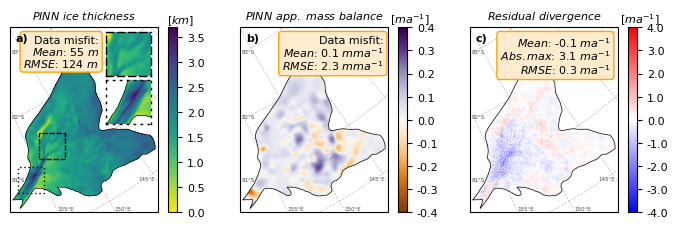

In [82]:
## Comparison to PINN-based thickness estimate

xg = np.unique(XH)
yg = np.unique(YH)
ix = np.searchsorted(xg,XH)
iy = np.searchsorted(yg,YH)
Hprofile = np.full((len(yg),len(xg)),np.nan)
Hprofile[iy,ix] = H_crop.reshape([len(H_crop),1])
Hprofile = np.flipud(Hprofile)

fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=[17.9*cm,6*cm],subplot_kw={"projection": proj})

""" PINN-H, PINN-a, MC-res
"""

data1 = sio.loadmat(f'{homepath}/saved-data/exp2-ice-thickness-BedMap-grid.mat')
data2 = sio.loadmat(f'{homepath}/saved-data/exp2-apparent-mass-balance-BedMap-grid.mat')
data3 = sio.loadmat(f'{homepath}/saved-data/exp2-pde-residual-Measures-grid.mat')
# data3 = sio.loadmat(f'{homepath}/saved-data/exp2-No1-pde-residual-Measures-grid.mat')

XH = data1['x']
YH = data1['y']
Xsmb = data2['x']
Ysmb = data2['y']
Xres = data3['x']
Yres = data3['y']

H = data1['mean_thickness']
smb = data2['mean_app_mb']
MCres = data3['mean_residual']

smb_diff = smb-spy*smb_crop
H_diff = Hprofile.flatten() - H

xdim = int((np.max(Xsmb)-np.min(Xsmb))/500) + 1
ydim = int((np.max(Ysmb)-np.min(Ysmb))/500) + 1

vmin = 0.
vmax = 3700.
vbound = 500

# cmap = 'viridis' # 'terrain' # 'gist_earth' # 'copper' # 
norm = mcolors.Normalize(vmin=vmin,vmax=vmax)
cmapdiff = 'bwr' # 'coolwarm' # 'seismic' # 

a1 = ax1.pcolormesh(XH,YH,H.reshape((XH.shape[0],XH.shape[1])),shading='gouraud',cmap='viridis_r',vmin=0,vmax=3700,transform=proj)
a2 = ax2.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb.reshape((ydim,xdim)),shading='gouraud',cmap='PuOr',vmin=-0.4,vmax=0.4,transform=proj)
a3 = ax3.pcolormesh(Xres,Yres,MCres.reshape((Xres.shape[0],Xres.shape[1])),shading='gouraud',cmap='bwr',vmin=-4,vmax=4,transform=proj)

x1, x2, y1, y2 = 3.85e5, 4.35e5, -9.55e5, -9.05e5  # subregion of the original image
axins1 = ax1.inset_axes(
    [0.65, 0.36, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai1 = axins1.pcolormesh(XH,YH,H.reshape((XH.shape[0],XH.shape[1])),cmap='viridis_r',shading='gouraud',norm=norm)
axins1.set_aspect(1)

x1, x2, y1, y2 = 4.25e5, 4.75e5, -8.9e5, -8.4e5  # subregion of the original image
axins2 = ax1.inset_axes(
    [0.65, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai2 = axins2.pcolormesh(XH,YH,H.reshape((XH.shape[0],XH.shape[1])),cmap='viridis_r',shading='gouraud',norm=norm)
axins1.set_aspect(1)

rect1,conn1 = ax1.indicate_inset_zoom(axins1, edgecolor="black")
rect2,conn2 = ax1.indicate_inset_zoom(axins2, edgecolor="black")


for conn in [conn1,conn2]:
    for c in conn:
        c.set_visible(False)

for axin in [axins1,axins2]:
    axin.set_xticks([])
    axin.set_yticks([])

for ax,a in zip([ax1, ax2, ax3, axins1, axins2],[a1, a2, a3, ai1, ai2]):
    outline = Polygon(vertices, closed=True, fill=False, edgecolor='black',linewidth=0.5)
    ax.add_patch(outline)

    ax.set_aspect(1)

    Artist.set_clip_path(a,outline)
    
for ax,a in zip([ax1, ax2, ax3],[a1, a2, a3]):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))

    ax.margins(x=0.02, y=0.02)
    # ax.set_aspect(1)

    gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=False,      # don't label the outside
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
    )
    gl.zorder = 0
    gl.xlocator = mticker.FixedLocator(range(-180, 181, 5))
    gl.ylocator = mticker.FixedLocator(range(-90, -59, 1))

    # Latitude labels
    for lat,y0 in zip(range(-83, -80, 1),[-687000,-812000,-932000]):
        ax.text(
            373000, y0,
            f"{-1*lat}°S",
            fontsize=fs-4,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            ),
            zorder=0
        )

    # Longitude labels
    for lon,x0,y0 in zip([155,150,145],[460000,570000,615000],[-987000,-987000,-930000]):
        ax.text(
            x0, y0,
            f"{lon}°E",
            fontsize=fs-4,
            color="0.3",
                bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )
    
    
# for ax,a in zip([ax1, ax2],[a1, a2]):
#     divider = make_axes_locatable(ax)
#     cax = divider.append_axes("right", size="5%", pad=0.05)
#     cbar = plt.colorbar(a,ax=ax,location='right',cax=cax)
#     cbar.ax.tick_params(labelsize=fs)
#     cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))

# for ax,a in zip([ax3],[a3]):
#     divider = make_axes_locatable(ax)
#     cax = divider.append_axes("right", size="5%", pad=0.05)
#     cbar = plt.colorbar(a,ax=ax,location='right',cax=cax)
#     cbar.ax.tick_params(labelsize=fs)

for ax,a,label in zip([ax1, ax2, ax3],[a1, a2, a3],['km','m a^{-1}','m a^{-1}']):
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.44)
    cbar.ax.tick_params(labelsize=fs)
    cbar.ax.set_title(f'$[{label}]$',fontsize=fs,x=1.3,pad=-0)
    if a in [a1]:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.1f}'))
    else:    
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1f}'))
    

for axin in [axins1]:#,axins3,axins5]:
    for spine in axin.spines.values():
        # spine.set_edgecolor('red')
        spine.set_linestyle((0,(1,4)))
        spine.set_linewidth(1)

for axin in [axins2]:#,axins4,axins6]:
    for spine in axin.spines.values():
        # spine.set_edgecolor('cyan')
        spine.set_linestyle((0,(5,3)))
        spine.set_linewidth(1)

for rect in [rect1]:#,rect3,rect5]:
    rect.set_linestyle((0,(1,2)))
    rect.set_linewidth(1)
    rect.set_edgecolor('black')
    rect.set_alpha(1)

for rect in [rect2]:#,rect4,rect6]:
    rect.set_linestyle((0,(4,1)))
    rect.set_linewidth(1)
    rect.set_edgecolor('black')
    rect.set_alpha(1)

for ax,diff,label in zip([ax1,ax2,ax3],[H_diff,1e3*smb_diff,MCres],['m','mm a^{-1}','m a^{-1}']):
    bbox = dict(boxstyle='round', fc='blanchedalmond', ec='orange', alpha=1)
    if ax == ax1:
        stats = ('Data misfit:\n'
                f'$Mean$: {np.nanmean(diff):.0f} ${label}$\n'
                f'$RMSE$: {np.sqrt(np.nanmean(np.square(diff))):.0f} ${label}$'
                )
        ax.text(0.6, 0.96, stats, fontsize=fs, bbox=bbox, transform=ax.transAxes, ha='right', va='top',linespacing=1)
    elif ax == ax2:
        stats = ('Data misfit:\n'
                f'$Mean$: {np.nanmean(diff):.1f} ${label}$\n'
                f'$RMSE$: {np.sqrt(np.nanmean(np.square(diff))):.1f} ${label}$'
                )
        ax.text(0.97, 0.96, stats, fontsize=fs, bbox=bbox, transform=ax.transAxes, ha='right', va='top',linespacing=1)
    elif ax == ax3:
        stats = (#'Data\ misfit:'
                f'$Mean$: {np.nanmean(diff):.1f} ${label}$\n'
                f'$Abs. max$: {np.nanmax((np.nanmax(diff),np.abs(np.nanmin(diff)))):.1f} ${label}$\n'
                f'$RMSE$: {np.sqrt(np.nanmean(np.square(diff))):.1f} ${label}$'
                )
        ax.text(0.95, 0.96, stats, fontsize=fs, bbox=bbox, transform=ax.transAxes, ha='right', va='top',linespacing=1)

# a,b,c
for label,ax in zip(['a','b','c'],[ax1,ax2,ax3]):
    ax.text(
        0.04, 0.97, f'{label})',
        transform=ax.transAxes,
        fontsize=fs,
        fontweight='bold',
        va='top',
        ha='left'
    )

# fig.suptitle('$Ice\ sheet\ bed\ elevation$')
ax1.set_title('$PINN\ ice\ thickness$',fontsize=fs)
ax2.set_title('$PINN\ app.\ mass\ balance$',fontsize=fs)
ax3.set_title('$Residual\ divergence$',fontsize=fs)

fig.tight_layout()

plt.savefig(f'{figurepath}Fig-comparison-PINN.jpg',dpi=900,pad_inches=0.,bbox_inches=None)


/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_99698/2928289917.py:51: RuntimeWarning: divide by zero encountered in divide
  H_drel = H_diff/Hprofile.flatten()
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_99698/2928289917.py:63: RuntimeWarning: All-NaN slice encountered
  H_diff_lr_pos = np.nanmax(H_diff_lr, axis=(1, 3))
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_99698/2928289917.py:64: RuntimeWarning: All-NaN slice encountered
  H_diff_lr_min = np.nanmin(H_diff_lr, axis=(1, 3))
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_99698/2928289917.py:115: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect1,conn1 = ax3.indicate_inset_zoom(axins1, edgecolor="black")
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_99698/2928

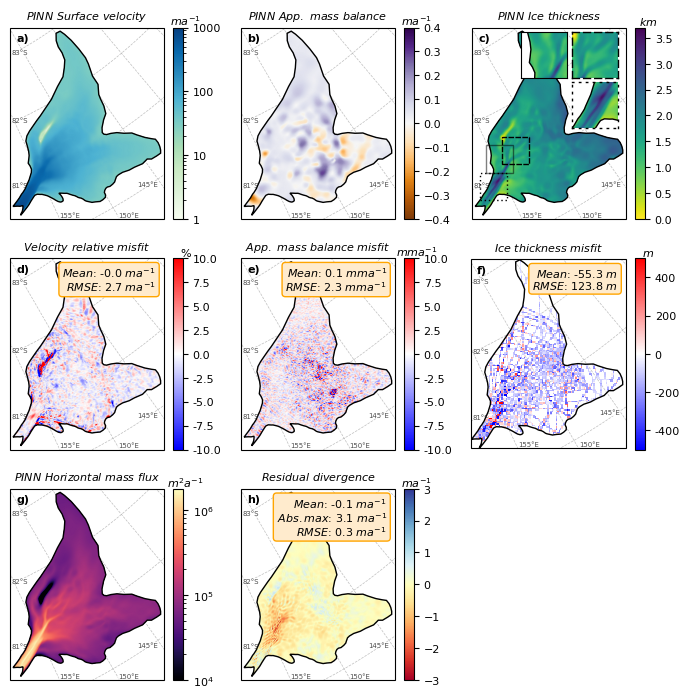

In [12]:
# all results PINN

fs = 8

# grid the radar lines
xg = np.unique(XH)
yg = np.unique(YH)
ix = np.searchsorted(xg,XH)
iy = np.searchsorted(yg,YH)
Hprofile = np.full((len(yg),len(xg)),np.nan)
Hprofile[iy,ix] = H_crop.reshape([len(H_crop),1])
Hprofile = np.flipud(Hprofile)

fig, ((ax1,ax2,ax3),(ax4,ax5,ax6),(ax7,ax8,ax9)) = plt.subplots(nrows=3,ncols=3,figsize=[17.9*cm,18*cm], subplot_kw={'projection':proj})

data1 = sio.loadmat(f'{homepath}/saved-data/exp2-ice-thickness-BedMap-grid.mat')
data2 = sio.loadmat(f'{homepath}/saved-data/exp2-apparent-mass-balance-BedMap-grid.mat')
data3 = sio.loadmat(f'{homepath}/saved-data/exp2-surface-velocity-Measures-grid.mat')
data4 = sio.loadmat(f'{homepath}/saved-data/exp2-pde-residual-Measures-grid.mat')
data5 = sio.loadmat(f'{homepath}/saved-data/exp2-ice-thickness-Measures-grid.mat')

Xbm = data1['x']
Ybm = data1['y']
Xsmb = data2['x'][:,0]
Ysmb = data2['y'][:,0]
Xvel = data3['x']
Yvel = data3['y']
Xpde = data4['x']
Ypde = data4['y']
XHmeas = data5['x']
YHmeas = data5['y']

xdim = int((np.max(Xsmb)-np.min(Xsmb))/500) + 1
ydim = int((np.max(Ysmb)-np.min(Ysmb))/500) + 1

H = data1['mean_thickness']
smb = data2['mean_app_mb'][0,:]
vel = data3['mean_velocity']
res = data4['mean_residual']
Hmeas = data5['mean_thickness']

vel_obs = spy*np.sqrt(vxcrop**2 + vycrop**2)
vel_diff = vel-vel_obs.flatten()
smb_diff = smb-spy*smb_crop
H_diff = H - Hprofile.flatten()

vel_drel = vel_diff/vel_obs.flatten()
smb_drel = smb_diff/(spy*smb_crop)
lim = 0.001
smb_drel = np.where(np.logical_or(spy*smb_crop>lim,spy*smb_crop<-lim),smb_drel,np.nan)
H_drel = H_diff/Hprofile.flatten()

# pool the H_diff
n = 5
H_diff_rs = H_diff.reshape((Xbm.shape[0],Xbm.shape[1]))
# H_diff_lr = H_diff_rs.reshape(-1, n, Xbm.shape[0]//n, n).sum((-1, -3)) / n
k, l = H_diff_rs.shape
pad = (-k % n, -l % n)
H_diff_rs_pad = np.pad(H_diff_rs, ((0, pad[0]), (0, pad[1])), constant_values=np.nan)
sign = np.where(H_diff_rs_pad<0,-1,1)
H_diff_lr = H_diff_rs_pad.reshape(H_diff_rs_pad.shape[0] // n, n,
                     H_diff_rs_pad.shape[1] // n, n)
H_diff_lr_pos = np.nanmax(H_diff_lr, axis=(1, 3))
H_diff_lr_min = np.nanmin(H_diff_lr, axis=(1, 3))
H_diff_lr = np.where(np.abs(H_diff_lr_min)>H_diff_lr_pos,H_diff_lr_min,H_diff_lr_pos)

vrel = 0.1 * 100.
norm_rel = TwoSlopeNorm(vmin=-1*vrel, vcenter=0., vmax=vrel)

cmapdiff = 'bwr'


a1 = ax1.pcolormesh(Xvel,Yvel,(vel).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap='GnBu',norm=LogNorm(vmin=1,vmax=1000),transform=proj)
a2 = ax2.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb.reshape((ydim,xdim)),shading='gouraud',cmap='PuOr',vmin=-0.4,vmax=0.4,transform=proj)#
a3 = ax3.pcolormesh(Xbm,Ybm,H.reshape((Xbm.shape[0],Xbm.shape[1])),shading='gouraud',cmap='viridis_r',vmin=0,vmax=3700,transform=proj)

## absolute differences
# a7 = ax7.pcolormesh(Xvel,Yvel,vel_diff.reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap=cmapdiff,vmax=20,vmin=-20,transform=proj)
a5 = ax5.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb_diff.reshape((ydim,xdim)),cmap=cmapdiff,shading='gouraud',vmin=-0.01,vmax=0.01,transform=proj)
a6 = ax6.pcolormesh(Xbm[::n,::n],Ybm[::n,::n],H_diff_lr,cmap=cmapdiff,vmin=-500.,vmax=500.,transform=proj)
# mask = np.where(~np.isnan(H_diff[0]))
# a9 = ax9.scatter(Xbm.flatten()[mask],Ybm.flatten()[mask],c=H_diff[0][mask],s=0.00001,marker='h',cmap=cmapdiff,vmin=-200.,vmax=200.)#,transform=proj)

## relative differences
a4 = ax4.pcolormesh(Xvel,Yvel,vel_drel.reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap=cmapdiff,vmax=0.1,vmin=-0.1,transform=proj)
# a8 = ax8.pcolormesh(Xsmb.reshape((ydim,xdim)),Ysmb.reshape((ydim,xdim)),smb_drel.reshape((ydim,xdim)),cmap=cmapdiff,shading='gouraud',vmin=-0.1,vmax=0.1,transform=proj)
# a9 = ax9.pcolormesh(Xbm,Ybm,H_drel.reshape((Xbm.shape[0],Xbm.shape[1])),cmap=cmapdiff,vmin=-0.1,vmax=0.1,transform=proj)
# mask = np.where(~np.isnan(H_drel[0]))
# a9 = ax9.scatter(Xbm.flatten()[mask],Ybm.flatten()[mask],c=H_drel[0][mask],s=0.00001,marker='h',cmap=cmapdiff,vmin=-200.,vmax=200.)#,transform=proj)

a7 = ax7.pcolormesh(Xvel,Yvel,(vel*Hmeas).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap='magma',norm=LogNorm(vmin=1e4),transform=proj)
a8 = ax8.pcolormesh(Xpde,Ypde,res.reshape((Xpde.shape[0],Xpde.shape[1])),shading='gouraud',cmap='RdYlBu',vmin=-3,vmax=3,transform=proj)

x1, x2, y1, y2 = 3.85e5, 4.35e5, -9.55e5, -9.05e5  # subregion of the original image
axins1 = ax3.inset_axes(
    [0.65, 0.36, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai1 = axins1.pcolormesh(Xbm,Ybm,H.reshape((Xbm.shape[0],Xbm.shape[1])),cmap='viridis_r',shading='gouraud',vmin=0,vmax=3700)
axins1.set_aspect(1)

x1, x2, y1, y2 = 4.25e5, 4.75e5, -8.9e5, -8.4e5  # subregion of the original image
axins2 = ax3.inset_axes(
    [0.65, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai2 = axins2.pcolormesh(Xbm,Ybm,H.reshape((Xbm.shape[0],Xbm.shape[1])),cmap='viridis_r',shading='gouraud',vmin=0,vmax=3700)
axins2.set_aspect(1)

x1, x2, y1, y2 = 3.95e5, 4.45e5, -9.05e5, -8.55e5  # subregion of the original image
axins3 = ax3.inset_axes(
    [0.32, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai3 = axins3.pcolormesh(Xbm,Ybm,H.reshape((Xbm.shape[0],Xbm.shape[1])),cmap='viridis_r',shading='gouraud',vmin=0,vmax=3700)
axins3.set_aspect(1)

rect1,conn1 = ax3.indicate_inset_zoom(axins1, edgecolor="black")
rect2,conn2 = ax3.indicate_inset_zoom(axins2, edgecolor="black")
rect3,conn3 = ax3.indicate_inset_zoom(axins3, edgecolor="black")

for conn in [conn1,conn2,conn3]:#,conn3,conn4,conn5,conn6]:
    for c in conn:
        c.set_visible(False)

for axin in [axins1,axins2,axins3]:#,axins3,axins4,axins5,axins6]:
    axin.set_xticks([])
    axin.set_yticks([])

for ax,a in zip([ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, axins1, axins2, axins3],[a1, a2, a3, a4, a5, a6, a7, a8, ai1, ai2, ai3]):
    outline = Polygon(vertices, closed=True, fill=False, edgecolor='black')
    ax.add_patch(outline)
    Artist.set_clip_path(a,outline)
    ax.set_aspect(1)

for ax,a in zip([ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8],[a1, a2, a3, a4, a5, a6, a7, a8]):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))

    ax.margins(x=0.02, y=0.02)

    gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=False,      # don't label the outside
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
    )
    gl.zorder = 0
    gl.xlocator = mticker.FixedLocator(range(-180, 181, 5))
    gl.ylocator = mticker.FixedLocator(range(-90, -59, 1))

    # Latitude labels
    for lat,y0 in zip(range(-83, -80, 1),[-687000,-812000,-932000]):
        x0 = 373000+5e3 if ax==ax6 else 373000 
        ax.text(
            x0, y0,
            f"{-1*lat}°S",
            fontsize=fs-3,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            ),
            zorder=0
        )

    # Longitude labels
    for lon,x0,y0 in zip([155,150,145],[460000,570000,605000],[-987000,-987000,-930000]):
        y0 = y0+7e3 if ax==ax6 else y0
        ax.text(
            x0, y0,
            f"{lon}°E",
            fontsize=fs-3,
            color="0.3",
                bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )
    
for ax,a,label in zip([ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8],[a1, a2, a3, a4, a5, a6, a7, a8],['m a^{-1}','m a^{-1}','km','\%','mm a^{-1}','m','m^2 a^{-1}','m a^{-1}']):
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.97)
    cbar.ax.tick_params(labelsize=fs)
    cbar.ax.set_title(f'${label}$',fontsize=fs,x=1.3,pad=-0)
    if ax in [ax3]:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.1f}'))
    # absolute differences {
    elif ax in [ax1,ax6]:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}'))
    elif ax in [ax5]:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e3:.1f}')) # }
    # relative difference {
    elif ax in [ax4]:
        cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.1f}')) # }
    # else:
    #     cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1f}'))

for ax,diff,label in zip([ax4,ax5,ax6,ax8],[vel_diff,1000*smb_diff,H_diff,res],['m a^{-1}','mm a^{-1}','m','m a^{-1}']):
    stats = (f'$Mean$: {np.nanmean(diff):.1f} ${label}$\n'
            f'$RMSE$: {np.sqrt(np.nanmean(np.square(diff))):.1f} ${label}$'
            )
    if ax==ax8:
        stats = (#'Data\ misfit:'
                f'$Mean$: {np.nanmean(diff):.1f} ${label}$\n'
                f'$Abs. max$: {np.nanmax((np.nanmax(diff),np.abs(np.nanmin(diff)))):.1f} ${label}$\n'
                f'$RMSE$: {np.sqrt(np.nanmean(np.square(diff))):.1f} ${label}$'
                )
    bbox = dict(boxstyle='round', fc='blanchedalmond', ec='orange', alpha=1)
    ax.text(0.95, 0.96, stats, fontsize=fs, bbox=bbox, transform=ax.transAxes, ha='right', va='top',linespacing=1)

# a,b,c
for label,ax in zip(['a','b','c','d','e','f','g','h'],[ax1,ax2,ax3,ax4,ax5,ax6,ax7,ax8]):
    ax.text(
        0.04, 0.97, f'{label})',
        transform=ax.transAxes,
        fontsize=fs,
        fontweight='bold',
        va='top',
        ha='left'
    )

for axin in [axins1]:#,axins3,axins5]:
    for spine in axin.spines.values():
        # spine.set_edgecolor('red')
        spine.set_linestyle((0,(1,4)))
        spine.set_linewidth(1)

for axin in [axins2]:#,axins4,axins6]:
    for spine in axin.spines.values():
        # spine.set_edgecolor('cyan')
        spine.set_linestyle((0,(5,3)))
        spine.set_linewidth(1)

for rect in [rect1]:#,rect3,rect5]:
    rect.set_linestyle((0,(1,2)))
    rect.set_linewidth(1)
    rect.set_edgecolor('black')
    rect.set_alpha(1)

for rect in [rect2]:#,rect4,rect6]:
    rect.set_linestyle((0,(4,1)))
    rect.set_linewidth(1)
    rect.set_edgecolor('black')
    rect.set_alpha(1)

ax1.set_title('$PINN\ Surface\ velocity$',fontsize=fs)
ax2.set_title('$PINN\ App.\ mass\ balance$',fontsize=fs)
ax3.set_title('$PINN\ Ice\ thickness$',fontsize=fs)
ax4.set_title('$Velocity\ relative\ misfit$',fontsize=fs)
ax5.set_title('$App.\ mass\ balance\ misfit$',fontsize=fs)
ax6.set_title('$Ice\ thickness\ misfit$',fontsize=fs)
ax7.set_title('$PINN\ Horizontal\ mass\ flux$',fontsize=fs)
ax8.set_title('$Residual\ divergence$',fontsize=fs)

ax9.axis("off")

# plt.show()

fig.tight_layout()

plt.savefig(f'{figurepath}Fig-all-results-PINN-2.jpg',dpi=1200,pad_inches=0.,bbox_inches=None)


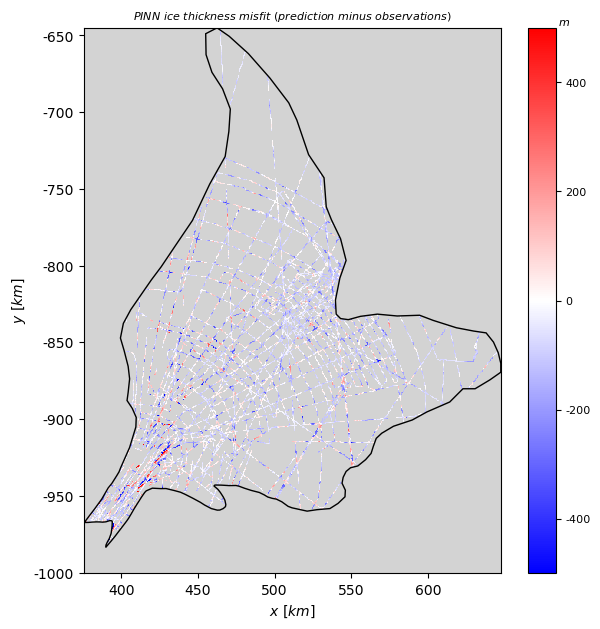

In [91]:
## Suppl. fig, run code in previous cell first
fig, ax = plt.subplots(nrows=1,ncols=1,figsize=[17.9*cm,18*cm])#, subplot_kw={'projection':proj})

ax.set_facecolor("lightgrey") 
a = ax.pcolormesh(Xbm,Ybm,H_diff.reshape((Xbm.shape[0],Xbm.shape[1])),cmap=cmapdiff,vmin=-500.,vmax=500.)#,transform=proj)

outline = Polygon(vertices, closed=True, fill=False, edgecolor='black')
ax.add_patch(outline)
Artist.set_clip_path(a,outline)
ax.set_aspect(1)

ax.set_xlabel('$x\ [km]$')
ax.set_ylabel('$y\ [km]$')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))

cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.97)
cbar.ax.tick_params(labelsize=fs)
cbar.ax.set_title(f'$m$',fontsize=fs,x=1.3,pad=-0)
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}'))

ax.set_title('$PINN\ ice\ thickness\ misfit\ (prediction\ minus\ observations)$',fontsize=fs)
plt.savefig(f'{figurepath}Fig-suppl-PINN-thickness-misfit.jpg',dpi=1200,pad_inches=0.,bbox_inches=None)